# Hierarchical Drift-Diffusion Model (HDDM): Temporal Bisection Parameter Recovery Pipeline

This notebook implements a end-to-end **Parameter Recovery Analysis** for a Drift-Diffusion Model (DDM) applied to a **Temporal Bisection Task**. It validates that a hierarchical Bayesian model fit using PyMC and Markov Chain Monte Carlo (MCMC) sampling can reliably recover participant-level ground-truth parameters from simulated decision-making and response time (RT) data.

---

## ⏳ Task Mechanics & Behavioral Simulation

In a **Temporal Bisection Task**, participants evaluate stimulus durations relative to learned anchor values (e.g., Short = $0.5\text{ s}$, Long = $2.0\text{ s}$):
* **Drift Rate Scaling ($v_{\text{trial}}$):** Drift rate is modeled as a function of stimulus duration relative to the anchor midpoint ($\text{Midpoint} = 1.25\text{ s}$):
  $$v_{\text{trial}} = v_{\text{scale}} \cdot (\text{Duration} - \text{Midpoint})$$
  * **Short Durations ($< 1.25\text{ s}$):** Produce negative drift rates driving evidence toward the lower boundary ($0 \implies \text{"Short" response}$).
  * **Long Durations ($> 1.25\text{ s}$):** Produce positive drift rates driving evidence toward the upper boundary ($a \implies \text{"Long" response}$).
* **Trial-Level Simulation:** Uses a Wiener diffusion process loop with time step $\Delta t = 1\text{ ms}$ across $N = 50$ synthetic participants, each evaluating 6 tested stimulus durations ($0.5\text{ s}$ to $2.0\text{ s}$).

---

## 🛠 Pipeline Architecture & Workflow

### 1. Behavioral Data Preprocessing
* **Error Response Flipping:** Applies `hddm.utils.flip_errors(data)` to sign-flip RTs for lower-boundary responses, creating unified bimodal RT distributions for correct vs. error choices across subjects.
* **Condition Partitioning:** Splits stimulus durations into categorical `duration_class` bins (`short` vs. `long`) to estimate condition-dependent drift rates ($v_{\text{short}}$ and $v_{\text{long}}$) in HDDM.

### 2. Parallel MCMC Model Fitting & Convergence Diagnostics
* **Parallel Chain Execution:** Runs $2$ independent MCMC chains simultaneously across CPU cores via Python's `multiprocessing.Process` module, executing $5,000$ iterations per chain with a $500$-iteration burn-in.
* **Model Selection (DIC):** Automatically selects the optimal reference model based on the lowest Deviance Information Criterion (DIC).
* **Gelman-Rubin ($\hat{R}$) Diagnostics:** Evaluates sampling convergence across independent chains ($\hat{R} < 1.1$).

### 3. Dynamic Parameter Extraction
* Parses subject-level parameter trace nodes (`v_subj(short)`, `v_subj(long)`, `a_subj`, `t_subj`, `z_subj`) from `model.nodes_db`.
* Constructs a unified summary table (`merged_df`) comparing True Generated parameters against HDDM Recovered posterior means.
* Exports results to `parameter_recovery_output/bisection_recovered_parameters.csv`.

---

## 📊 Diagnostic Visualizations & Output Artifacts

All figures are automatically generated and saved at high resolution ($300\text{ DPI}$) inside the `parameter_recovery_output/` folder:

1. **Task Simulation Overview (`simulation_task_curves.png`):**
   * **Subplot A:** DDM evidence accumulation trajectories $x(t)$ for Subject 0 under Short ($0.5\text{ s}$) and Long ($2.0\text{ s}$) durations.
   * **Subplots B & C:** Individual participant ($N=5$) and Pooled ($\text{Mean} \pm \text{SEM}$) Psychometric Curves ($\text{P}(\text{"Long"})$ vs. Stimulus Duration).
   * **Subplots D & E:** Individual participant ($N=5$) and Pooled ($\text{Mean} \pm \text{SEM}$) Response Time curves across durations.

2. **Subject-Level RT Distributions (`rt_distributions.png`):**
   * Stepped histograms displaying flipped error/correct RT distributions across all 50 participants.

3. **Parameter Density Comparison (`two_stage_parameter_recovery_density.png`):**
   * Overlays Kernel Density Estimation (KDE) distributions for True vs. Recovered values across all parameters ($v_{\text{short}}, v_{\text{long}}, a, t, z$).
   * Annotated with Pearson correlation coefficients ($r$) and exact $p$-values.

4. **Scatter Plots with Ideal Identity Reference (`two_stage_parameter_recovery_scatter.png`):**
   * Regression scatter plots (`sns.regplot`) comparing True vs. Recovered values alongside an ideal $y = x$ reference line.

5. **ArviZ-Style Posterior Overlay & 94% HDI (`arviz_style_direct_plot.png`):**
   * Minimalist Bayesian posterior density overlays comparing population fitted vs. recovered means with horizontal **94% High-Density Interval (HDI)** bars.

6. **Comparative Forest Plot (`direct_forest_plot.png`):**
   * Forest plot summarizing true vs. recovered population-level means and $95\%$ Confidence Intervals across parameters.

---

## 🚀 Generated Artifacts Table

| Output File Path | Description |
| :--- | :--- |
| `parameter_recovery_output/bisection_recovered_parameters.csv` | Full CSV summary of individual subject ground-truth vs. recovered parameters. |
| `parameter_recovery_output/simulation_task_curves.png` | DDM trajectories, psychometric curves, and RT curves. |
| `parameter_recovery_output/rt_distributions.png` | Individual participant response time distributions with flipped error RTs. |
| `parameter_recovery_output/two_stage_parameter_recovery_density.png` | Overlaid KDE density comparisons (True vs. Recovered). |
| `parameter_recovery_output/two_stage_parameter_recovery_scatter.png` | Scatter regression plots with ideal $y=x$ reference lines. |
| `parameter_recovery_output/arviz_style_direct_plot.png` | ArviZ-style posterior KDE overlays with annotated 94% HDI bounds. |
| `parameter_recovery_output/direct_forest_plot.png` | Forest plot comparing true vs. recovered parameter means and 95% CIs. |

Simulating Temporal Bisection Task Data...


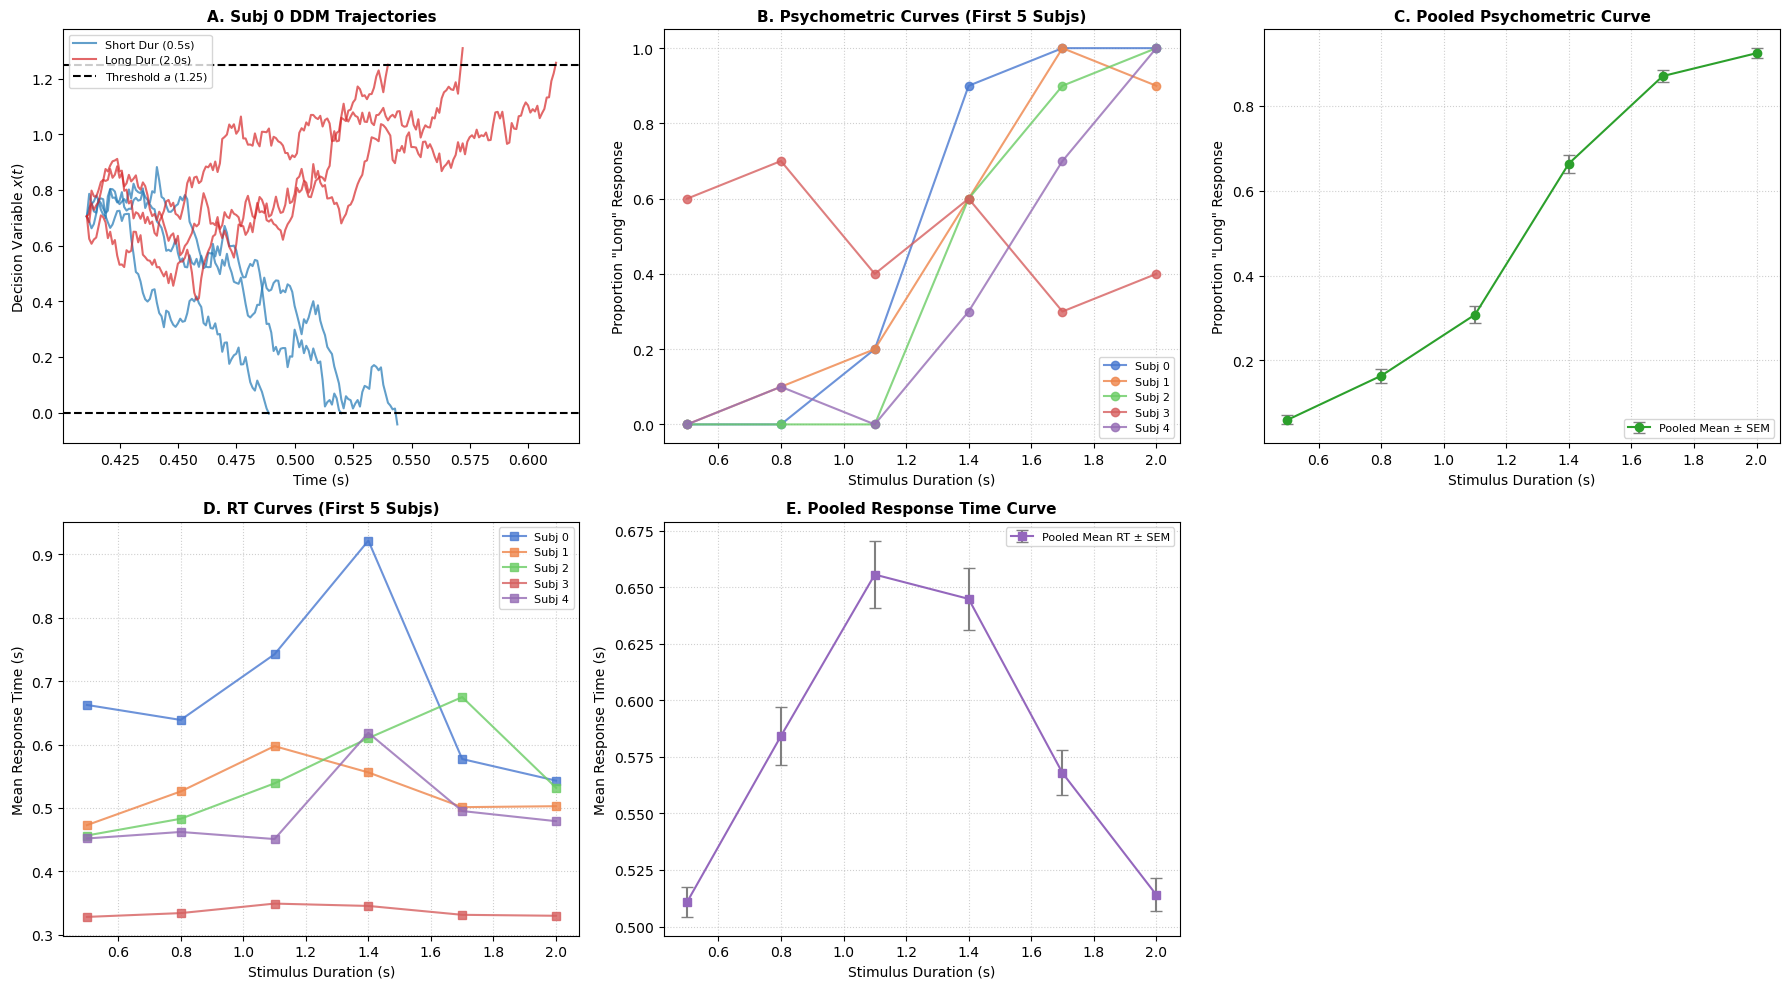

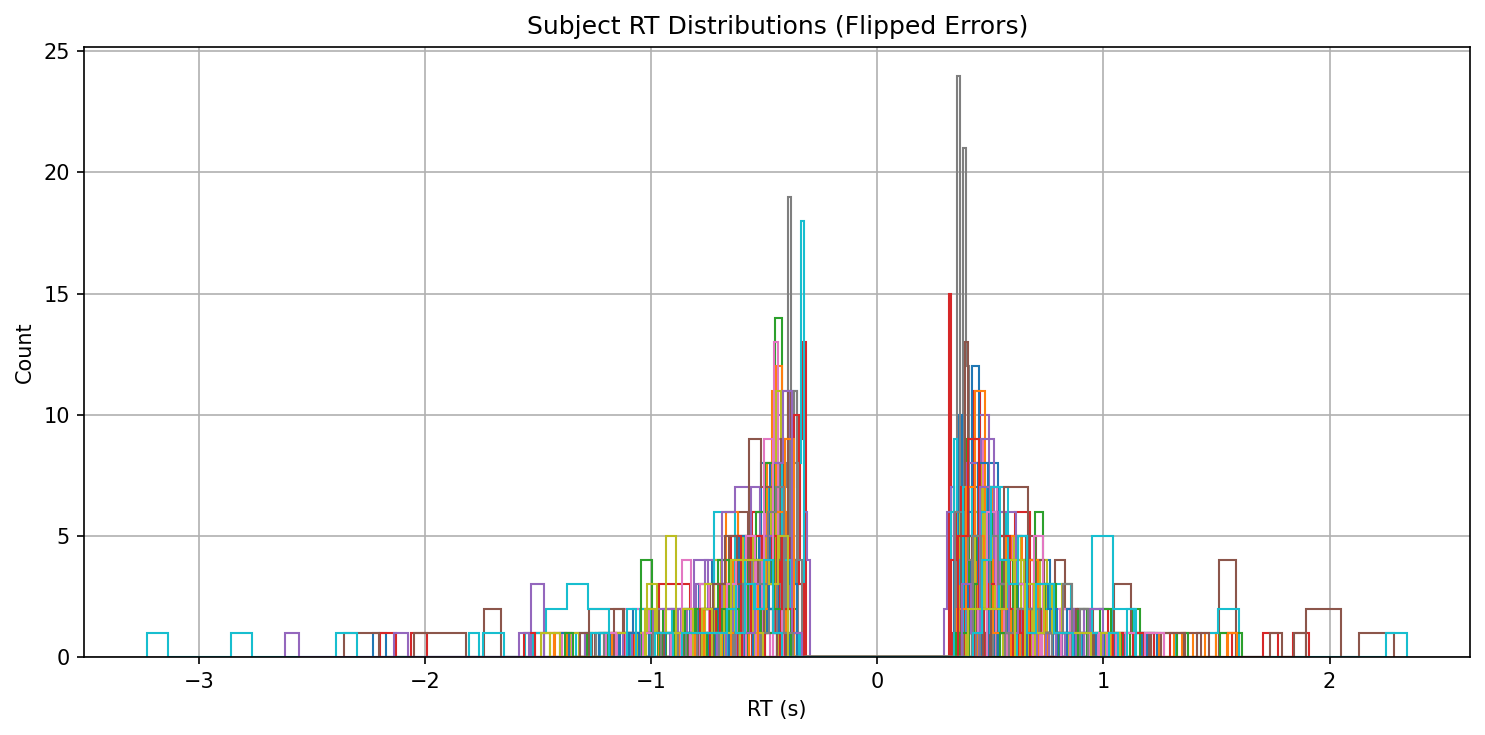


[Parallel MCMC] Launching independent MCMC sampling chains...
Starting Chain 1 on PID 13703...
No model attribute --> setting up standard HDDM
Starting Chain 2 on PID 13705...
No model attribute --> setting up standard HDDM
Set model to ddm
Set model to ddm


/opt/conda/lib/python3.9/site-packages/scipy/optimize/_optimize.py:2309: RuntimeWarning: invalid value encountered in double_scalars
  tmp2 = (x - v) * (fx - fw)
/opt/conda/lib/python3.9/site-packages/scipy/optimize/_optimize.py:2309: RuntimeWarning: invalid value encountered in double_scalars
  tmp2 = (x - v) * (fx - fw)


 [                  0%                  ] 8 of 5000 complete in 0.5 sec[                  0%                  ] 8 of 5000 complete in 0.5 sec[                  0%                  ] 15 of 5000 complete in 1.0 sec[                  0%                  ] 15 of 5000 complete in 1.0 sec[                  0%                  ] 22 of 5000 complete in 1.5 sec[                  0%                  ] 23 of 5000 complete in 1.6 sec[                  0%                  ] 30 of 5000 complete in 2.1 sec[                  0%                  ] 31 of 5000 complete in 2.2 sec[                  0%                  ] 37 of 5000 complete in 2.6 sec[                  0%                  ] 39 of 5000 complete in 2.7 sec[                  0%                  ] 44 of 5000 complete in 3.1 sec[                  0%                  ] 47 of 5000 complete in 3.3 sec[                  1%                  ] 52 of 5000 complete in 3.7 sec[                  1%                  ] 54 of 5000 complete in 3.8 sec[      

 [---               8%                  ] 441 of 5000 complete in 31.4 sec[---               8%                  ] 449 of 5000 complete in 31.8 sec[---               8%                  ] 449 of 5000 complete in 32.0 sec[---               9%                  ] 457 of 5000 complete in 32.3 sec[---               9%                  ] 457 of 5000 complete in 32.5 sec[---               9%                  ] 465 of 5000 complete in 32.9 sec[---               9%                  ] 464 of 5000 complete in 33.0 sec[---               9%                  ] 473 of 5000 complete in 33.4 sec[---               9%                  ] 471 of 5000 complete in 33.5 sec[---               9%                  ] 480 of 5000 complete in 34.0 sec[---               9%                  ] 478 of 5000 complete in 34.1 sec[---               9%                  ] 488 of 5000 complete in 34.5 sec[---               9%                  ] 486 of 5000 complete in 34.6 sec[---               9%                  ] 496 of 50

 [------           17%                  ] 878 of 5000 complete in 62.4 sec[------           17%                  ] 886 of 5000 complete in 62.6 sec[------           17%                  ] 886 of 5000 complete in 63.0 sec[------           17%                  ] 894 of 5000 complete in 63.1 sec[------           17%                  ] 894 of 5000 complete in 63.5 sec[------           18%                  ] 902 of 5000 complete in 63.7 sec[------           18%                  ] 902 of 5000 complete in 64.1 sec[------           18%                  ] 909 of 5000 complete in 64.2 sec[------           18%                  ] 910 of 5000 complete in 64.6 sec[------           18%                  ] 917 of 5000 complete in 64.8 sec[------           18%                  ] 918 of 5000 complete in 65.2 sec[-------          18%                  ] 925 of 5000 complete in 65.3 sec[-------          18%                  ] 926 of 5000 complete in 65.8 sec[-------          18%                  ] 932 of 50

 [---------        26%                  ] 1308 of 5000 complete in 92.6 sec[---------        26%                  ] 1305 of 5000 complete in 92.8 sec[---------        26%                  ] 1315 of 5000 complete in 93.2 sec[---------        26%                  ] 1312 of 5000 complete in 93.3 sec[----------       26%                  ] 1322 of 5000 complete in 93.7 sec[----------       26%                  ] 1319 of 5000 complete in 93.8 sec[----------       26%                  ] 1329 of 5000 complete in 94.2 sec[----------       26%                  ] 1326 of 5000 complete in 94.3 sec[----------       26%                  ] 1336 of 5000 complete in 94.7 sec[----------       26%                  ] 1333 of 5000 complete in 94.8 sec[----------       26%                  ] 1343 of 5000 complete in 95.2 sec[----------       26%                  ] 1341 of 5000 complete in 95.4 sec[----------       27%                  ] 1351 of 5000 complete in 95.8 sec[----------       26%                

... (5 outputs left out)

 [-----------------75%--------          ] 3752 of 5000 complete in 268.2 sec[-----------------74%--------          ] 3739 of 5000 complete in 268.4 sec[-----------------75%--------          ] 3759 of 5000 complete in 268.7 sec[-----------------74%--------          ] 3746 of 5000 complete in 268.9 sec[-----------------75%--------          ] 3766 of 5000 complete in 269.2 sec[-----------------75%--------          ] 3753 of 5000 complete in 269.4 sec[-----------------75%--------          ] 3774 of 5000 complete in 269.8 sec[-----------------75%--------          ] 3761 of 5000 complete in 269.9 sec[-----------------75%--------          ] 3781 of 5000 complete in 270.3 sec[-----------------75%--------          ] 3768 of 5000 complete in 270.5 sec[-----------------75%--------          ] 3788 of 5000 complete in 270.9 sec[-----------------75%--------          ] 3775 of 5000 complete in 271.0 sec[-----------------75%--------          ] 3795 of 5000 complete in 271.4 sec[-----------------75%---

 [-----------------82%-----------       ] 4149 of 5000 complete in 297.0 sec[-----------------82%-----------       ] 4135 of 5000 complete in 297.2 sec[-----------------83%-----------       ] 4156 of 5000 complete in 297.6 sec[-----------------82%-----------       ] 4142 of 5000 complete in 297.7 sec[-----------------83%-----------       ] 4163 of 5000 complete in 298.1 sec[-----------------82%-----------       ] 4149 of 5000 complete in 298.3 sec[-----------------83%-----------       ] 4171 of 5000 complete in 298.6 sec[-----------------83%-----------       ] 4156 of 5000 complete in 298.8 sec[-----------------83%-----------       ] 4178 of 5000 complete in 299.1 sec[-----------------83%-----------       ] 4163 of 5000 complete in 299.3 sec[-----------------83%-----------       ] 4185 of 5000 complete in 299.7 sec[-----------------83%-----------       ] 4170 of 5000 complete in 299.8 sec[-----------------83%-----------       ] 4192 of 5000 complete in 300.2 sec[-----------------83%---

 [-----------------90%--------------    ] 4549 of 5000 complete in 326.1 sec[-----------------90%--------------    ] 4536 of 5000 complete in 326.4 sec[-----------------91%--------------    ] 4556 of 5000 complete in 326.6 sec[-----------------90%--------------    ] 4543 of 5000 complete in 326.9 sec[-----------------91%--------------    ] 4563 of 5000 complete in 327.1 sec[-----------------91%--------------    ] 4550 of 5000 complete in 327.4 sec[-----------------91%--------------    ] 4571 of 5000 complete in 327.7 sec[-----------------91%--------------    ] 4557 of 5000 complete in 327.9 sec[-----------------91%--------------    ] 4578 of 5000 complete in 328.2 sec[-----------------91%--------------    ] 4564 of 5000 complete in 328.4 sec[-----------------91%--------------    ] 4585 of 5000 complete in 328.7 sec[-----------------91%--------------    ] 4571 of 5000 complete in 329.0 sec[-----------------91%--------------    ] 4592 of 5000 complete in 329.2 sec[-----------------91%---

 [-----------------98%----------------- ] 4946 of 5000 complete in 355.0 sec[-----------------98%----------------- ] 4933 of 5000 complete in 355.3 sec[-----------------99%----------------- ] 4953 of 5000 complete in 355.5 sec[-----------------98%----------------- ] 4940 of 5000 complete in 355.8 sec[-----------------99%----------------- ] 4960 of 5000 complete in 356.0 sec[-----------------98%----------------- ] 4947 of 5000 complete in 356.4 sec[-----------------99%----------------- ] 4967 of 5000 complete in 356.5 sec[-----------------99%----------------- ] 4954 of 5000 complete in 356.9 sec[-----------------99%----------------- ] 4974 of 5000 complete in 357.0 sec[-----------------99%----------------- ] 4961 of 5000 complete in 357.4 sec[-----------------99%----------------- ] 4981 of 5000 complete in 357.6 sec[-----------------99%----------------- ] 4968 of 5000 complete in 357.9 sec[-----------------99%----------------- ] 4988 of 5000 complete in 358.1 sec[-----------------99%---

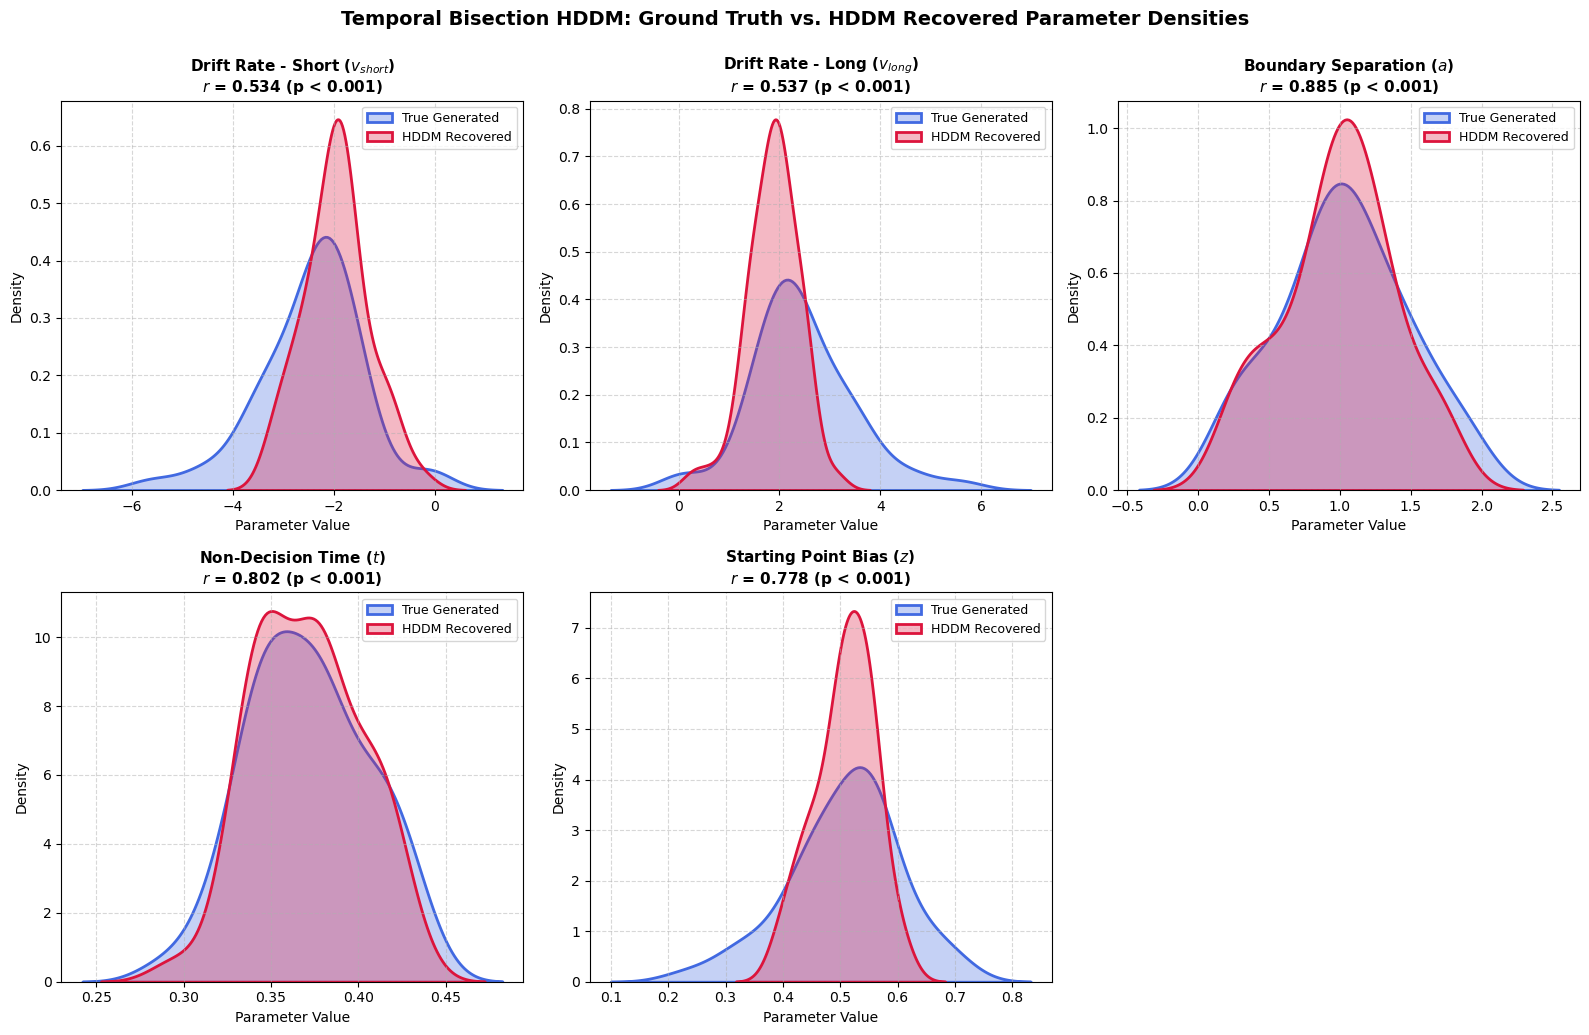

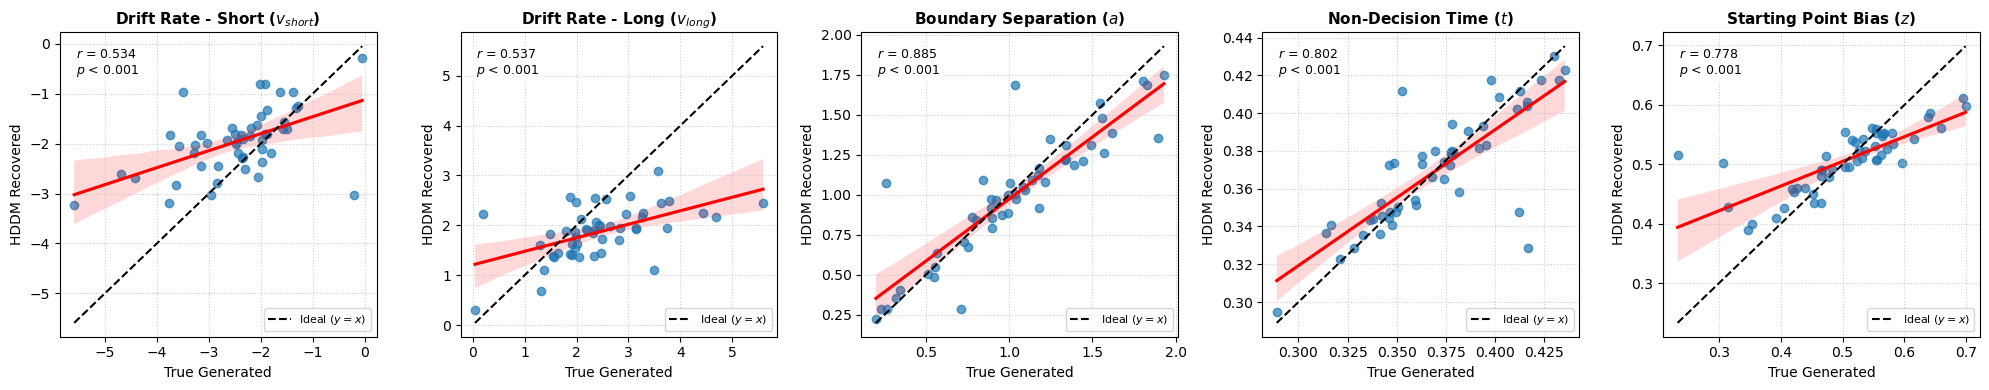

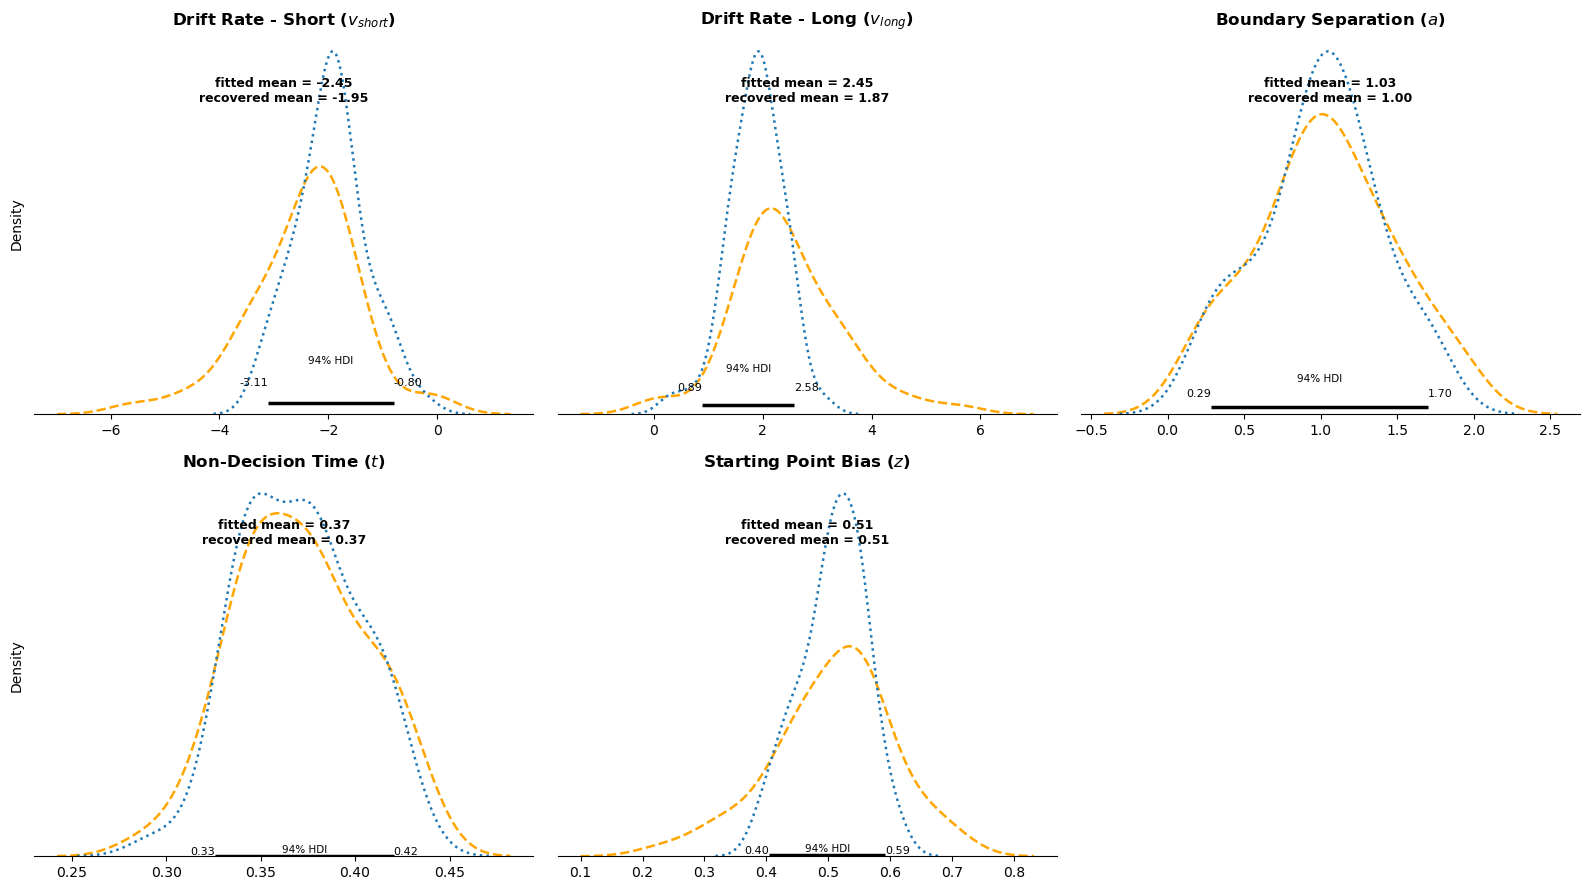

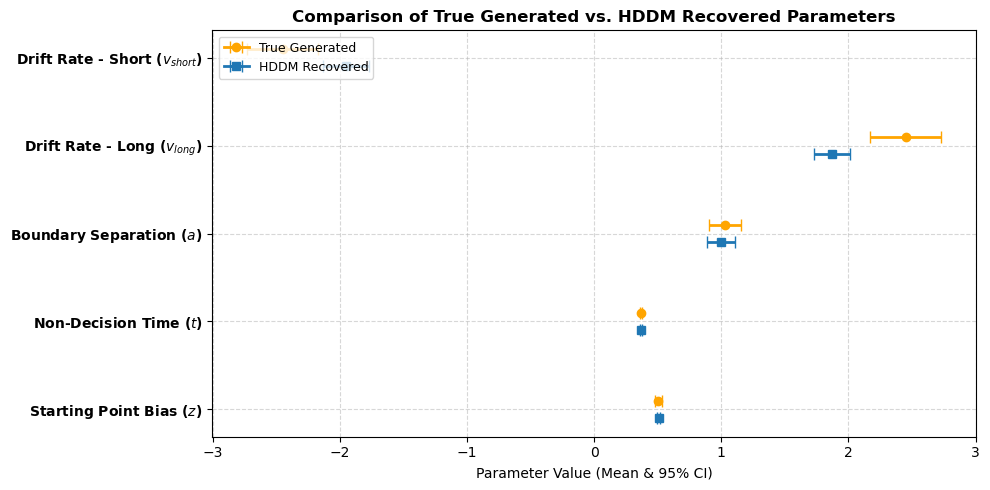


All sampling chains and diagnostic plots successfully completed and saved!


In [3]:
import os
import re
import multiprocessing as mp
import hddm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import pearsonr
import seaborn as sns

os.makedirs("parameter_recovery_output", exist_ok=True)
np.random.seed(42)

# ============================================================
# 1. SIMULATION FUNCTION FOR TEMPORAL BISECTION TASK
# ============================================================
def simulate_hddm_bisection(
    n_subjects=50,
    trials_per_duration=10,
    durations=[0.5, 0.8, 1.1, 1.4, 1.7, 2.0],
    short_anchor=0.5,
    long_anchor=2.0,
    v_mean=5.5,
    a_mean=1.0,
    z_mean=0.5,
    t_mean=0.35,
    v_std=2.0,
    a_std=0.5,
    z_std=0.1,
    t_std=0.04,
    dt=0.001,
    s=1.0,
    max_t=5.0
):
    """
    Simulates a Drift Diffusion Model for a Temporal Bisection Task with participant-level variability.
    """
    data = []
    subject_params = []
    anchor_mid = (short_anchor + long_anchor) / 2.0
    
    for subj in range(n_subjects):
        subj_a = np.maximum(0.2, np.random.normal(a_mean, a_std))
        subj_v_scale = np.maximum(0.1, np.random.normal(v_mean, v_std))
        subj_z_rel = np.clip(np.random.normal(z_mean, z_std), 0.1, 0.9)
        subj_t = np.maximum(0.05, np.random.normal(t_mean, t_std))
        subj_z_abs = subj_z_rel * subj_a
        
        subject_v_trials = []
        
        for dur in durations:
            v_trial = subj_v_scale * (dur - anchor_mid)
            
            for trial in range(trials_per_duration):
                subject_v_trials.append(v_trial)
                x = subj_z_abs
                current_time = subj_t
                
                while current_time < max_t:
                    x += v_trial * dt + np.sqrt(dt) * s * np.random.normal(0, 1)
                    current_time += dt
                    
                    if x >= subj_a:
                        response = 1
                        rt = current_time
                        break
                    elif x <= 0:
                        response = 0
                        rt = current_time
                        break
                else:
                    response = np.nan
                    rt = np.nan
                
                data.append({
                    'subj_idx': subj,
                    'duration': dur,
                    'rt': rt,
                    'response': response
                })
        
        subject_params.append({
            'subj_idx': subj,
            'v_scale_true': subj_v_scale,
            'v_mean_true': subject_v_trials,
            'a_true': subj_a,
            'z_true': subj_z_rel,
            'z_abs_true': subj_z_abs,
            't_true': subj_t
        })

    df_data = pd.DataFrame(data)
    df_params = pd.DataFrame(subject_params)
    
    return df_data, df_params

# ============================================================
# 2. RUN SIMULATION & GENERATE TASK VISUALIZATIONS
# ============================================================
print("Simulating Temporal Bisection Task Data...")
durations_to_test = [0.5, 0.8, 1.1, 1.4, 1.7, 2.0]
short_anchor, long_anchor = 0.5, 2.0
anchor_mid = (short_anchor + long_anchor) / 2.0

df_sim, df_true_parameters = simulate_hddm_bisection(
    n_subjects=50,
    trials_per_duration=10,
    durations=durations_to_test,
    short_anchor=short_anchor,
    long_anchor=long_anchor
)

# Plotting Task Trajectories and Behavioral Curves
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Subplot A: DDM Trajectories
subj_0_params = df_true_parameters.iloc[0]
a_s0, z_s0, t_s0, v_scale_s0 = subj_0_params['a_true'], subj_0_params['z_abs_true'], subj_0_params['t_true'], subj_0_params['v_scale_true']
dt, diff_s = 0.001, 1.0

for dur, color, label in [(0.5, '#1f77b4', 'Short Dur (0.5s)'), (2.0, '#d62728', 'Long Dur (2.0s)')]:
    v_trial = v_scale_s0 * (dur - anchor_mid)
    for path_idx in range(3):
        x, t = z_s0, t_s0
        path_x, path_t = [x], [t]
        while t < 3.0:
            x += v_trial * dt + np.sqrt(dt) * diff_s * np.random.normal(0, 1)
            t += dt
            path_x.append(x)
            path_t.append(t)
            if x >= a_s0 or x <= 0:
                break
        axes[0, 0].plot(path_t, path_x, color=color, alpha=0.7, label=label if path_idx == 0 else "")

axes[0, 0].axhline(a_s0, color='black', linestyle='--', label=f'Threshold $a$ ({a_s0:.2f})')
axes[0, 0].axhline(0, color='black', linestyle='--')
axes[0, 0].set_title("A. Subj 0 DDM Trajectories", fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel('Time (s)')
axes[0, 0].set_ylabel('Decision Variable $x(t)$')
axes[0, 0].legend(loc='upper left', fontsize=8)

# Subplot B: Psychometric Curves
subj_psycho = df_sim.groupby(['subj_idx', 'duration'])['response'].mean().reset_index()
sample_subjs = subj_psycho['subj_idx'].unique()[:5]
palette = sns.color_palette("muted", 5)

for i, subj in enumerate(sample_subjs):
    subset = subj_psycho[subj_psycho['subj_idx'] == subj]
    axes[0, 1].plot(subset['duration'], subset['response'], marker='o', color=palette[i], alpha=0.8, label=f'Subj {subj}')

axes[0, 1].set_title('B. Psychometric Curves (First 5 Subjs)', fontsize=11, fontweight='bold')
axes[0, 1].set_xlabel('Stimulus Duration (s)')
axes[0, 1].set_ylabel('Proportion "Long" Response')
axes[0, 1].legend(loc='lower right', fontsize=8)
axes[0, 1].grid(True, linestyle=':', alpha=0.6)

# Subplot C: Pooled Psychometric Curve
pooled_psycho = df_sim.groupby('duration')['response'].agg(['mean', 'sem']).reset_index()
axes[0, 2].errorbar(pooled_psycho['duration'], pooled_psycho['mean'], yerr=pooled_psycho['sem'], 
                    fmt='-o', color='#2ca02c', ecolor='gray', elinewidth=1.5, capsize=4, label='Pooled Mean ± SEM')
axes[0, 2].set_title('C. Pooled Psychometric Curve', fontsize=11, fontweight='bold')
axes[0, 2].set_xlabel('Stimulus Duration (s)')
axes[0, 2].set_ylabel('Proportion "Long" Response')
axes[0, 2].legend(loc='lower right', fontsize=8)
axes[0, 2].grid(True, linestyle=':', alpha=0.6)

# Subplot D: RT Curves
subj_rt = df_sim.groupby(['subj_idx', 'duration'])['rt'].mean().reset_index()
for i, subj in enumerate(sample_subjs):
    subset = subj_rt[subj_rt['subj_idx'] == subj]
    axes[1, 0].plot(subset['duration'], subset['rt'], marker='s', color=palette[i], alpha=0.8, label=f'Subj {subj}')

axes[1, 0].set_title('D. RT Curves (First 5 Subjs)', fontsize=11, fontweight='bold')
axes[1, 0].set_xlabel('Stimulus Duration (s)')
axes[1, 0].set_ylabel('Mean Response Time (s)')
axes[1, 0].legend(loc='upper right', fontsize=8)
axes[1, 0].grid(True, linestyle=':', alpha=0.6)

# Subplot E: Pooled RT Curve
pooled_rt = df_sim.groupby('duration')['rt'].agg(['mean', 'sem']).reset_index()
axes[1, 1].errorbar(pooled_rt['duration'], pooled_rt['mean'], yerr=pooled_rt['sem'], 
                    fmt='-s', color='#9467bd', ecolor='gray', elinewidth=1.5, capsize=4, label='Pooled Mean RT ± SEM')
axes[1, 1].set_title('E. Pooled Response Time Curve', fontsize=11, fontweight='bold')
axes[1, 1].set_xlabel('Stimulus Duration (s)')
axes[1, 1].set_ylabel('Mean Response Time (s)')
axes[1, 1].legend(loc='upper right', fontsize=8)
axes[1, 1].grid(True, linestyle=':', alpha=0.6)

fig.delaxes(axes[1, 2])
plt.tight_layout()
plt.savefig("parameter_recovery_output/simulation_task_curves.png", dpi=300, bbox_inches="tight")
plt.show()

# ============================================================
# 3. PREPROCESS DATA FOR HDDM & PLOT FLIPPED ERROR RTs
# ============================================================
# Flip error RTs
df_sim_flipped = hddm.utils.flip_errors(df_sim.copy())

fig = plt.figure(figsize=(10, 5), dpi=150)
ax = fig.add_subplot(111, xlabel='RT (s)', ylabel='Count', title='Subject RT Distributions (Flipped Errors)')
for i, subj_data in df_sim_flipped.groupby('subj_idx'):
    subj_data.rt.hist(bins=60, histtype='step', ax=ax)

plt.tight_layout()
plt.savefig("parameter_recovery_output/rt_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

# Add duration_class (short vs long) for condition dependence in HDDM
mean_duration = df_sim['duration'].mean()
df_sim['duration_class'] = np.where(df_sim['duration'] < mean_duration, 'short', 'long')
df_sim['duration_class'] = df_sim['duration_class'].astype(str)

# Calculate true mean drift rate for short and long conditions
df_true_parameters['v_true_short'] = df_true_parameters['v_mean_true'].apply(
    lambda lst: np.mean([v for v in lst if v < 0]) if isinstance(lst, (list, np.ndarray)) else np.nan
)
df_true_parameters['v_true_long'] = df_true_parameters['v_mean_true'].apply(
    lambda lst: np.mean([v for v in lst if v > 0]) if isinstance(lst, (list, np.ndarray)) else np.nan
)

# ============================================================
# 4. PARALLEL SAMPLING HELPER FUNCTION
# ============================================================
def run_chain(chain_idx, data_df, queue):
    """Worker function to run a single MCMC chain in parallel."""
    print(f"Starting Chain {chain_idx + 1} on PID {os.getpid()}...")
    model = hddm.HDDM(
        data_df, 
        include=['v', 'a', 't', 'z'],
        depends_on={'v': 'duration_class'},
        informative=True,
        is_group_model=True
    )
    model.find_starting_values()
    model.sample(5000, burn=500, dbname=f'traces_chain_{chain_idx}.db', db='pickle')
    queue.put((chain_idx, model))

if __name__ == '__main__':
    n_chains = 2
    queue = mp.Queue()
    processes = []

    print("\n[Parallel MCMC] Launching independent MCMC sampling chains...")
    for i in range(n_chains):
        p = mp.Process(target=run_chain, args=(i, df_sim, queue))
        processes.append(p)
        p.start()

    models_dict = {}
    for _ in range(n_chains):
        chain_idx, m = queue.get()
        models_dict[chain_idx] = m

    for p in processes:
        p.join()

    models = [models_dict[i] for i in range(n_chains)]

    # ============================================================
    # CONVERGENCE & MODEL SELECTION METRICS
    # ============================================================
    print("\n[Model Selection] Deviance Information Criterion (DIC) for all chains:")
    dic_values = [m.dic for m in models]
    for i, dic_val in enumerate(dic_values):
        print(f"  • Chain {i+1} DIC: {dic_val:.3f}")

    best_chain_idx = np.argmin(dic_values)
    model = models[best_chain_idx]
    print(f"\n=> Selecting Chain {best_chain_idx + 1} as primary model (Lowest DIC: {dic_values[best_chain_idx]:.3f})")

    print("\n[Convergence Diagnostic] Gelman-Rubin (R-hat) Statistics:")
    gr_stats = hddm.analyze.gelman_rubin(models)
    gr_df = pd.DataFrame.from_dict(gr_stats, orient='index', columns=['R_hat']).sort_values('R_hat', ascending=False)
    print(gr_df.head(20))

    # ============================================================
    # 5. PARAMETER EXTRACTION & MERGE
    # ============================================================
    rec_v_short, rec_v_long, rec_a, rec_t, rec_z = [], [], [], [], []
    n_subs = len(df_true_parameters)

    nodes_db = model.nodes_db.copy()

    for subj in range(n_subs):
        v_short_val, v_long_val, a_val, t_val, z_val = np.nan, np.nan, np.nan, np.nan, np.nan
        for idx_name in nodes_db.index:
            name_str = str(idx_name)
            if f".{subj}" in name_str or f"({subj})" in name_str:
                if 'v' in name_str:
                    if 'short' in name_str.lower():
                        v_short_val = nodes_db.loc[idx_name, "mean"]
                    elif 'long' in name_str.lower():
                        v_long_val = nodes_db.loc[idx_name, "mean"]
                if name_str.startswith("a_subj") or name_str.startswith("a."):
                    a_val = nodes_db.loc[idx_name, "mean"]
                elif name_str.startswith("t_subj") or name_str.startswith("t."):
                    t_val = nodes_db.loc[idx_name, "mean"]
                elif name_str.startswith("z_subj") or name_str.startswith("z."):
                    z_val = nodes_db.loc[idx_name, "mean"]

        rec_v_short.append(v_short_val)
        rec_v_long.append(v_long_val)
        rec_a.append(a_val)
        rec_t.append(t_val)
        rec_z.append(z_val)

    merged_df = df_true_parameters.copy()
    merged_df["v_rec_short"] = rec_v_short
    merged_df["v_rec_long"] = rec_v_long
    merged_df["a_recovered"] = rec_a
    merged_df["t_recovered"] = rec_t
    merged_df["z_recovered"] = rec_z

    merged_df.to_csv("parameter_recovery_output/bisection_recovered_parameters.csv", index=False)
    print("\nRecovered parameters successfully saved to 'parameter_recovery_output/bisection_recovered_parameters.csv'!")

    # Parameters to evaluate across plots
    parameters_to_check = [
        ("v_true_short", "v_rec_short", "Drift Rate - Short ($v_{short}$)"),
        ("v_true_long", "v_rec_long", "Drift Rate - Long ($v_{long}$)"),
        ("a_true", "a_recovered", "Boundary Separation ($a$)"),
        ("t_true", "t_recovered", "Non-Decision Time ($t$)"),
        ("z_true", "z_recovered", "Starting Point Bias ($z$)"),
    ]

    # ============================================================
    # PLOT 1: DENSITY COMPARISON PLOTS (KDE)
    # ============================================================
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    axes = axes.flatten()

    for i, (true_col, rec_col, title) in enumerate(parameters_to_check):
        ax = axes[i]
        sub_df = merged_df[[true_col, rec_col]].apply(pd.to_numeric, errors="coerce").dropna()

        sns.kdeplot(data=sub_df[true_col], ax=ax, color="royalblue", fill=True, alpha=0.3, linewidth=2, label="True Generated")
        sns.kdeplot(data=sub_df[rec_col], ax=ax, color="crimson", fill=True, alpha=0.3, linewidth=2, label="HDDM Recovered")

        r, p_val = pearsonr(sub_df[true_col], sub_df[rec_col])
        p_str = "p < 0.001" if p_val < 0.001 else f"p = {p_val:.3f}"

        ax.set_title(f"{title}\n$r$ = {r:.3f} ({p_str})", fontsize=11, fontweight="bold")
        ax.set_xlabel("Parameter Value")
        ax.set_ylabel("Density")
        ax.legend(loc="upper right", fontsize=9)
        ax.grid(True, linestyle="--", alpha=0.5)

    fig.delaxes(axes[5])
    plt.tight_layout()
    plt.suptitle("Temporal Bisection HDDM: Ground Truth vs. HDDM Recovered Parameter Densities", y=1.03, fontsize=14, weight="bold")
    plt.savefig("parameter_recovery_output/two_stage_parameter_recovery_density.png", dpi=300, bbox_inches="tight")
    plt.show()

    # ============================================================
    # PLOT 2: INDIVIDUAL REGRESSION & SCATTER WITH IDENTITY LINES (y = x)
    # ============================================================
    def regplot_with_corr(x, y, ax, title):
        sub_df = pd.DataFrame({'x': x, 'y': y}).dropna()
        if len(sub_df) < 2:
            ax.text(0.5, 0.5, "Insufficient data", ha='center', va='center')
            return
        r, p_val = pearsonr(sub_df['x'], sub_df['y'])
        p_str = "$p$ < 0.001" if p_val < 0.001 else f"$p$ = {p_val:.3f}"
        
        sns.regplot(data=sub_df, x='x', y='y', ax=ax, scatter_kws={'alpha': 0.7, 'color': '#1f77b4'}, line_kws={'color': 'red'})
        
        min_val = min(sub_df['x'].min(), sub_df['y'].min())
        max_val = max(sub_df['x'].max(), sub_df['y'].max())
        ax.plot([min_val, max_val], [min_val, max_val], 'k--', lw=1.5, label='Ideal ($y=x$)')
        
        text = f"$r$ = {r:.3f}\n{p_str}"
        ax.text(0.05, 0.95, text, transform=ax.transAxes, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='none'), fontsize=9)
        ax.set_title(title, fontsize=11, fontweight='bold')
        ax.set_xlabel("True Generated")
        ax.set_ylabel("HDDM Recovered")
        ax.legend(loc='lower right', fontsize=8)
        ax.grid(True, linestyle=':', alpha=0.6)

    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    for i, (true_col, rec_col, title) in enumerate(parameters_to_check):
        sub_df = merged_df[[true_col, rec_col]].dropna()
        regplot_with_corr(x=sub_df[true_col], y=sub_df[rec_col], ax=axes[i], title=title)

    plt.tight_layout()
    plt.savefig("parameter_recovery_output/two_stage_parameter_recovery_scatter.png", dpi=300, bbox_inches='tight')
    plt.show()

    # ============================================================
    # PLOT 3: ARVIZ-STYLE OVERLAY WITH 94% HDI
    # ============================================================
    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    axes = axes.flatten()

    for i, (true_col, rec_col, title) in enumerate(parameters_to_check):
        ax = axes[i]
        sub_df = merged_df[[true_col, rec_col]].apply(pd.to_numeric, errors='coerce').dropna()
        
        vals_true = sub_df[true_col].values
        vals_rec = sub_df[rec_col].values
        
        mean_true = np.mean(vals_true)
        mean_rec = np.mean(vals_rec)
        hdi_rec = np.percentile(vals_rec, [3, 97])
        
        sns.kdeplot(x=vals_true, ax=ax, color="orange", linestyle="dashed", label="fitted", lw=1.8)
        sns.kdeplot(x=vals_rec, ax=ax, color="tab:blue", linestyle="dotted", label="recovered", lw=1.8)
        
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_visible(False)
        ax.set_yticks([])
        ax.set_ylabel('Density' if i % 3 == 0 else '', fontsize=10)
        ax.set_title(title, fontsize=12, fontweight='bold')
        
        ax.text(0.5, 0.82, f"fitted mean = {mean_true:.2f}\nrecovered mean = {mean_rec:.2f}", 
                transform=ax.transAxes, ha='center', fontsize=9, fontweight='bold')
        
        ax.hlines(y=0.02, xmin=hdi_rec[0], xmax=hdi_rec[1], color='black', linewidth=2.5)
        ax.text(hdi_rec[0], 0.05, f"{hdi_rec[0]:.2f}", ha='right', fontsize=8)
        ax.text(hdi_rec[1], 0.05, f"{hdi_rec[1]:.2f}", ha='left', fontsize=8)
        ax.text(np.mean(hdi_rec), 0.09, "94% HDI", ha='center', fontsize=7.5)

    fig.delaxes(axes[5])
    plt.tight_layout()
    plt.savefig("parameter_recovery_output/arviz_style_direct_plot.png", dpi=300, bbox_inches='tight')
    plt.show()

    # ============================================================
    # PLOT 4: FOREST PLOT COMPARATIVE (MEANS & 95% CI)
    # ============================================================
    fig, ax = plt.subplots(figsize=(10, 5))

    y_ticks = np.arange(len(parameters_to_check))
    labels = [p[2] for p in parameters_to_check]

    for idx, (true_col, rec_col, title) in enumerate(parameters_to_check):
        sub_df = merged_df[[true_col, rec_col]].apply(pd.to_numeric, errors='coerce').dropna()
        
        true_mean = sub_df[true_col].mean()
        true_ci = 1.96 * sub_df[true_col].sem()
        
        rec_mean = sub_df[rec_col].mean()
        rec_ci = 1.96 * sub_df[rec_col].sem()
        
        ax.errorbar(true_mean, idx - 0.1, xerr=true_ci, fmt='o-', color='orange', label='True Generated' if idx == 0 else "", capsize=4, lw=2)
        ax.errorbar(rec_mean, idx + 0.1, xerr=rec_ci, fmt='s-', color='tab:blue', label='HDDM Recovered' if idx == 0 else "", capsize=4, lw=2)

    ax.set_yticks(y_ticks)
    ax.set_yticklabels(labels, fontweight='bold')
    ax.invert_yaxis()
    ax.set_xlabel("Parameter Value (Mean & 95% CI)")
    ax.set_title("Comparison of True Generated vs. HDDM Recovered Parameters", fontsize=12, fontweight='bold')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.savefig("parameter_recovery_output/direct_forest_plot.png", dpi=300, bbox_inches='tight')
    plt.show()

    print("\nAll sampling chains and diagnostic plots successfully completed and saved!")

Plotting a
Plotting a_std
Plotting v(long)
Plotting v(short)
Plotting v_std
Plotting t
Plotting t_std
Plotting z
Plotting z_std


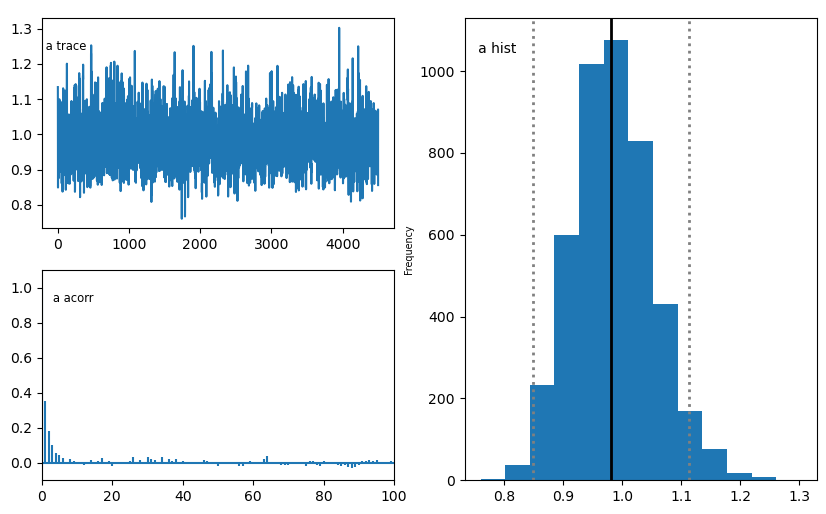

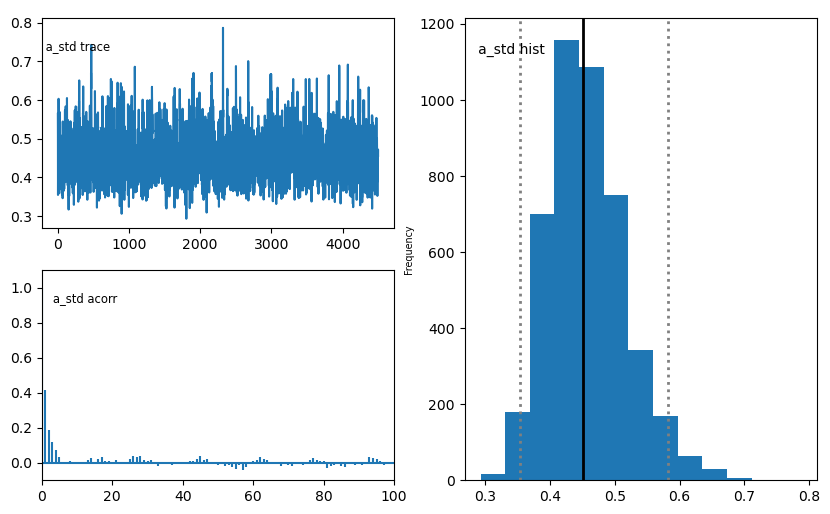

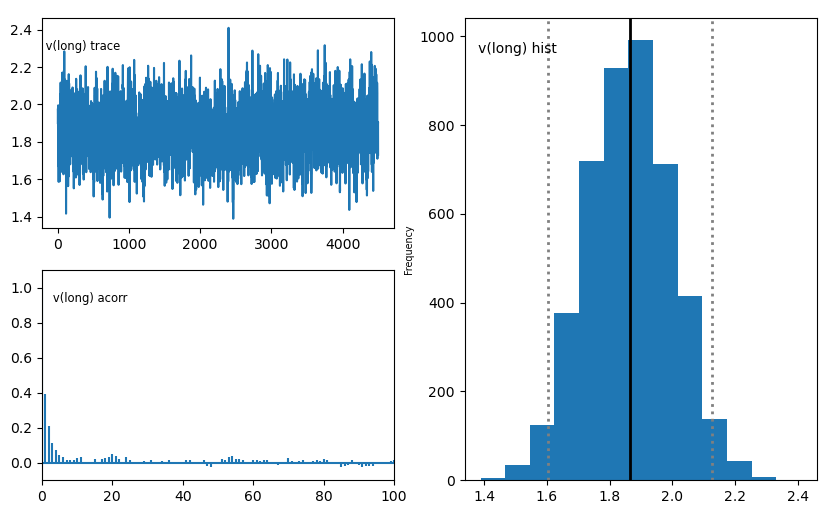

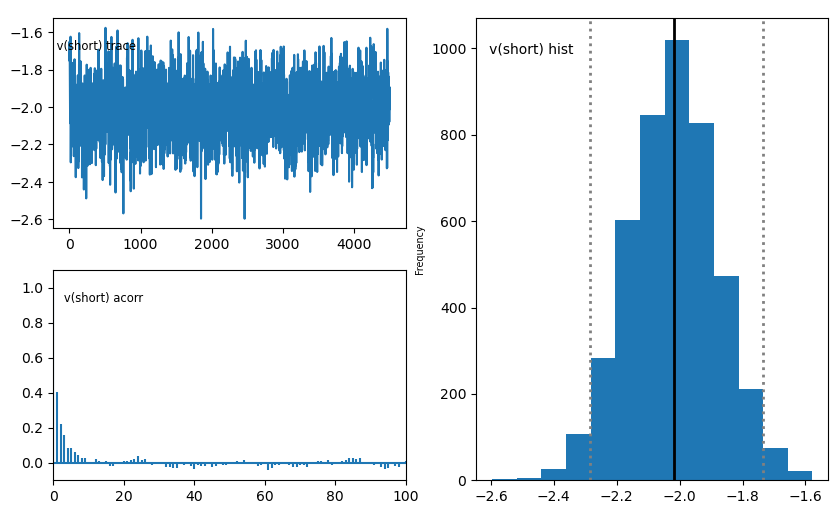

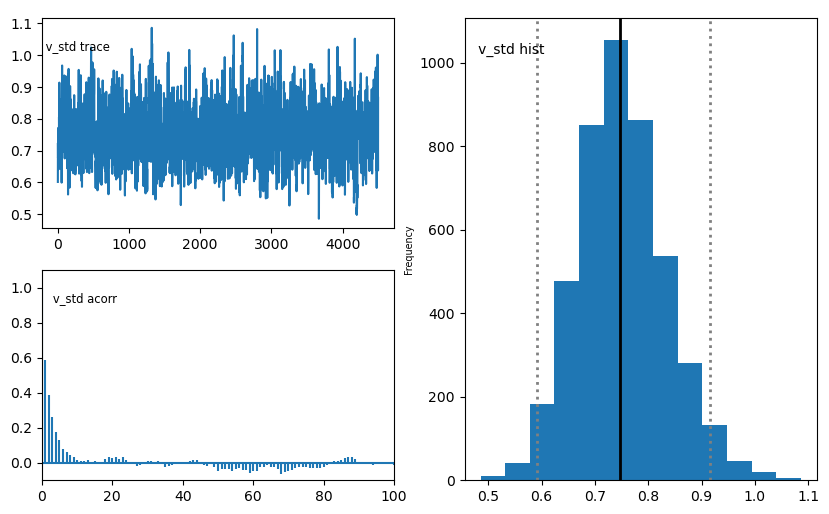

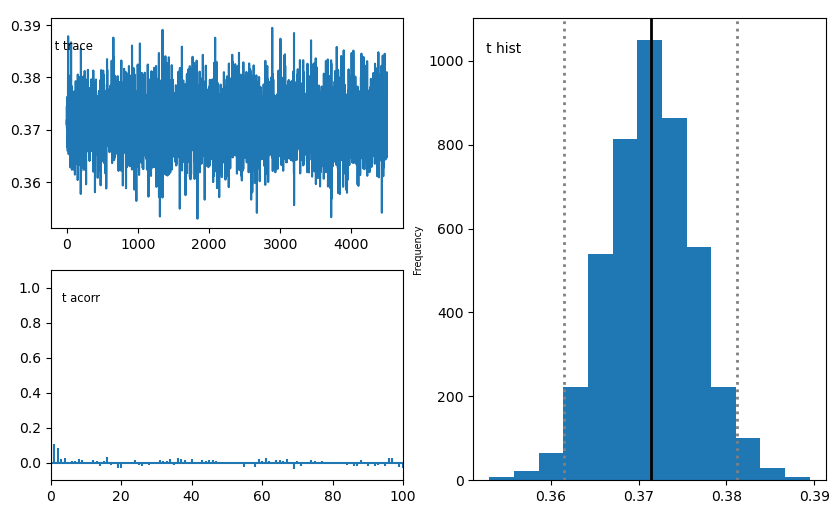

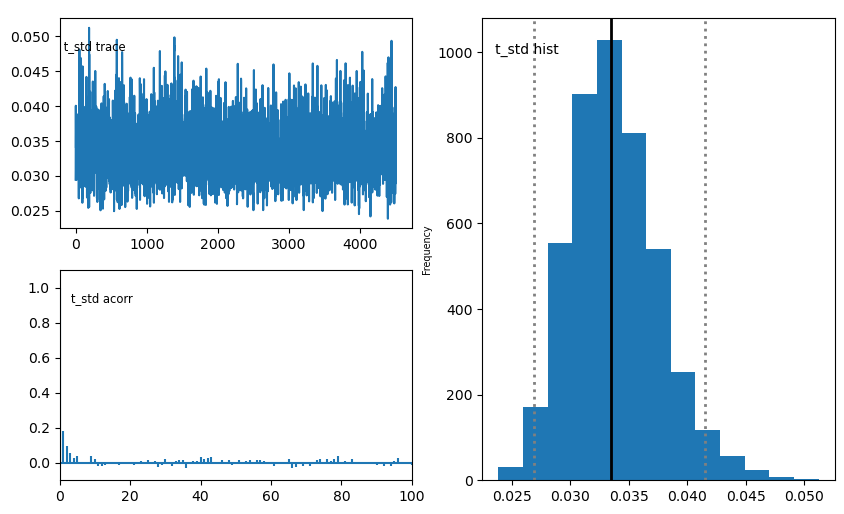

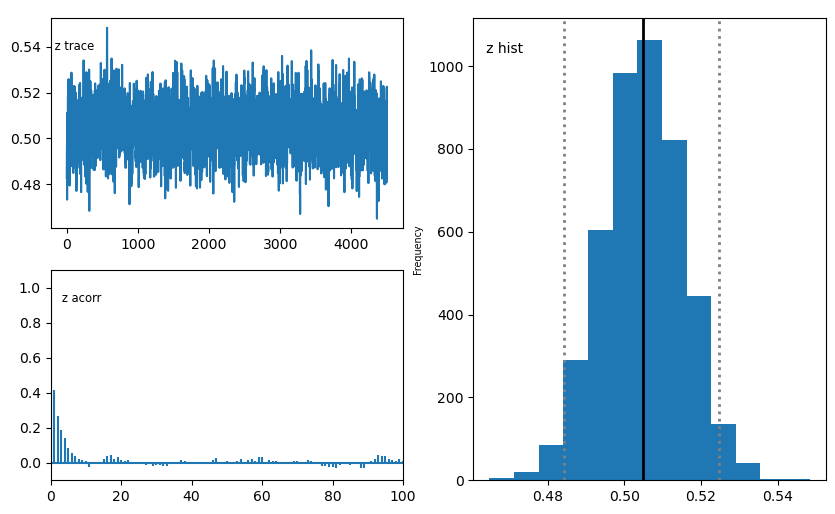

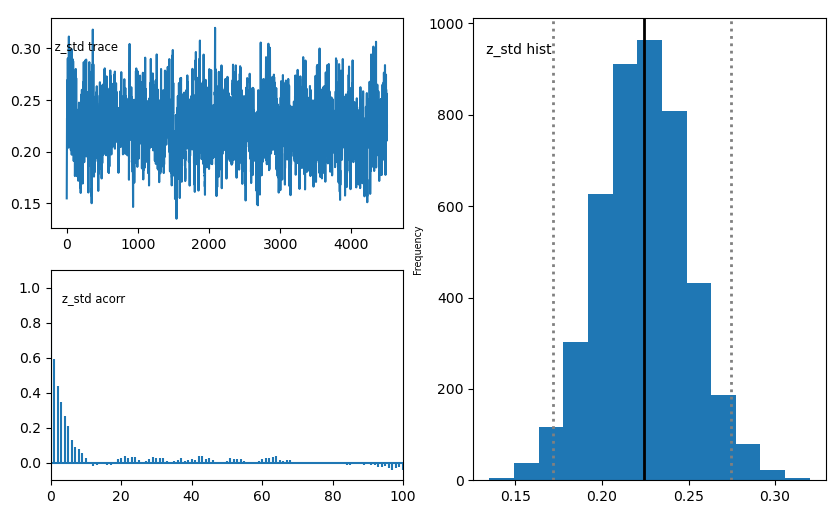

In [4]:
model.plot_posteriors()

# Two-Stage Hierarchical Drift-Diffusion Model (HDDM): Parameter Recovery Pipeline

This notebook implements a parameter recovery analysis for a **Two-Stage Drift Diffusion Model** applied to a **Temporal Bisection Task**. The goal is to evaluate whether standard Bayesian MCMC estimation (via HDDM) can reliably recover participant-level ground-truth parameters when the data-generating process involves two distinct sequential decision phases.

---

## ⏳ Two-Stage Decision Mechanics

The simulated task consists of two phases per trial:
1. **Stage 1 (Stimulus Encoding Phase, $t < \text{duration}$):** Evidence accumulates at baseline rate $v_1$ during physical stimulus presentation.
2. **Stage 2 (Post-Offset Decision Phase, $t \ge \text{duration}$):** Upon stimulus offset, evidence accumulation switches dynamically to $v_2$, driven by the accumulated state $x_{\text{offset}}$ relative to the decision threshold midpoint ($a/2$).
   * $x_{\text{offset}} < a/2 \implies$ Drives evidence towards $0$ ("Short" boundary).
   * $x_{\text{offset}} \ge a/2 \implies$ Drives evidence towards $a$ ("Long" boundary).

---

## 🛠 Pipeline Architecture & Workflow

### 1. Data Preparation & Normalization
* **Normalized Initial Bias ($z_2$):** Calculates relative offset bias $z_2 = \text{clip}(x_{\text{offset}} / a_{\text{true}}, 0, 1)$ to quantify starting state variability prior to Stage 2.
* **Error Response Flipping:** Uses `hddm.utils.flip_errors(data)` to create unified bimodal RT distributions.

### 2. Parallel MCMC Fitting & Convergence Diagnostics
* **Parallel Chains:** Executes $2$ independent MCMC chains in parallel using Python's `multiprocessing.Process` module ($5,000$ iterations, $1,000$ burn-in per chain).
* **Model Selection:** Automatically selects the chain with the minimum Deviance Information Criterion (DIC).
* **Gelman-Rubin Diagnostics:** Confirms sampling convergence across parameters ($\hat{R} < 1.1$).

### 3. Parameter Extraction
* Dynamically extracts subject-level parameter trace nodes (`v_subj(short)`, `v_subj(long)`, `a_subj`, `t_subj`, `z_subj`).
* Exports the merged ground-truth vs. recovered dataset to `parameter_recovery_output/stage2_recovered_parameters.csv`.

---

## 📊 Diagnostic Visualizations & Output Artifacts

All figures are exported at $300\text{ DPI}$ to the `parameter_recovery_output/` directory:

1. **Two-Stage Task Trajectories & Curves (`two_stage_bisection_trajectories.png`):**
   * Multi-panel figure displaying Phase 1 vs. Phase 2 decision variable trajectories alongside individual ($N=5$) and pooled psychometric and response time curves.

2. **Subject RT Distributions (`rt_distributions.png`):**
   * Stepped histograms showing error-flipped response times across participants.

3. **Parameter Density Comparison (`two_stage_parameter_recovery_density.png`):**
   * Overlaid KDE plots comparing ground-truth vs. recovered parameter distributions ($v_{2,\text{short}}, v_{2,\text{long}}, a_2, t_2, z_2$) with Pearson correlations ($r$).

4. **Scatter Plots with Ideal Reference (`two_stage_parameter_recovery_scatter.png`):**
   * Linear regression scatter plots (`sns.regplot`) comparing participant-level true vs. recovered values against an ideal $y=x$ reference line.

5. **ArviZ-Style Posterior Overlay & 94% HDI (`arviz_style_direct_plot.png`):**
   * Minimalist Bayesian posterior density overlays with annotated fitted and recovered population means and **94% High-Density Interval (HDI)** bounds.

6. **Comparative Forest Plot (`direct_forest_plot.png`):**
   * Forest plot illustrating ground-truth vs. recovered population-level means and $95\%$ Confidence Intervals across all parameters.

---

## 🚀 Key Output Artifacts

| Output File Path | Description |
| :--- | :--- |
| `parameter_recovery_output/stage2_recovered_parameters.csv` | Summary CSV containing true vs. recovered subject-level parameters. |
| `parameter_recovery_output/two_stage_bisection_trajectories.png` | Phase 1/2 trajectories, psychometric, and RT curves. |
| `parameter_recovery_output/rt_distributions.png` | Individual participant response time distributions (error-flipped). |
| `parameter_recovery_output/two_stage_parameter_recovery_density.png` | KDE density comparison overlays across parameters. |
| `parameter_recovery_output/two_stage_parameter_recovery_scatter.png` | Scatter plots with regression and $y=x$ identity lines. |
| `parameter_recovery_output/arviz_style_direct_plot.png` | ArviZ-style posterior KDE overlays with 94% HDI bars. |
| `parameter_recovery_output/direct_forest_plot.png` | Forest plot comparing true vs. recovered means and 95% CIs. |

Running Two-Stage Temporal Bisection Simulation...


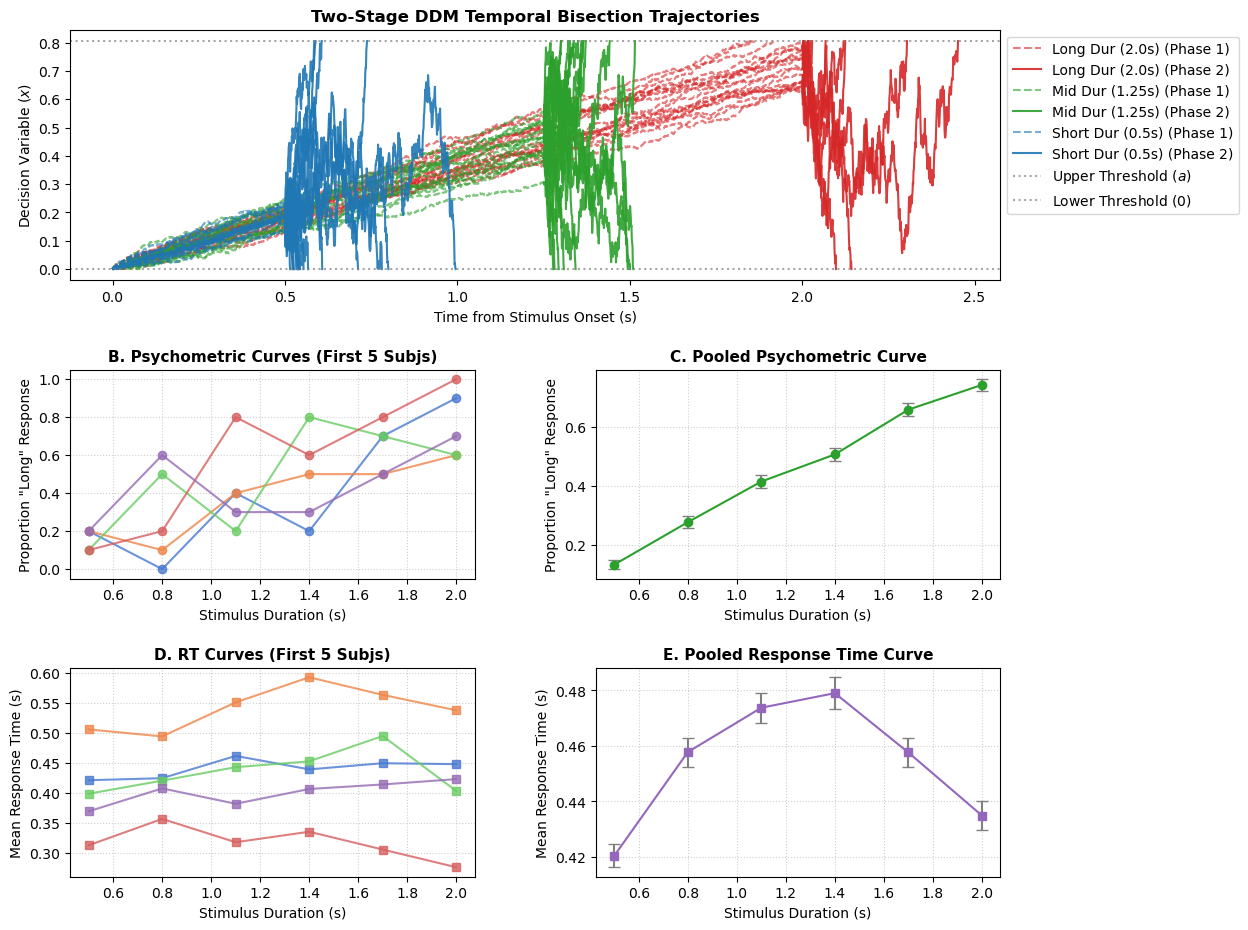

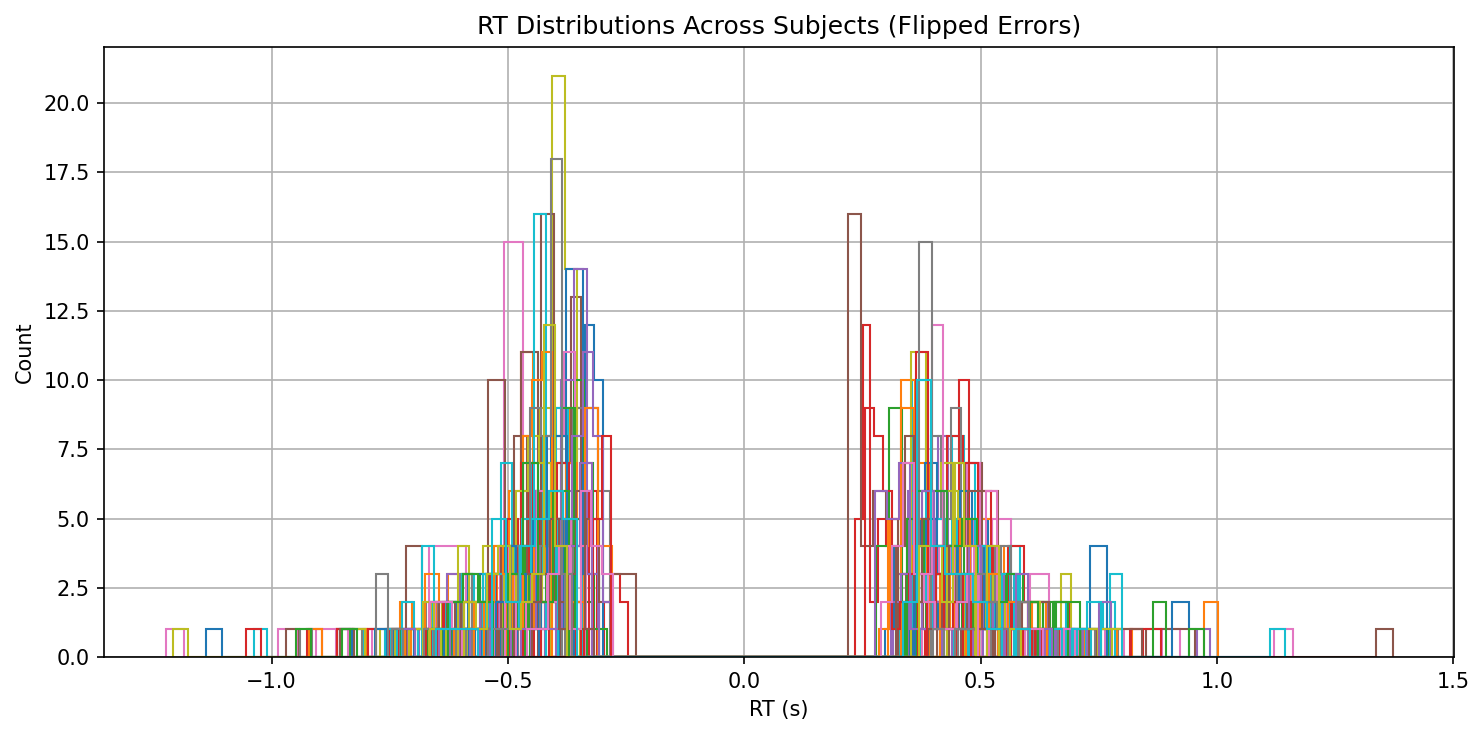


[Parallel MCMC] Launching independent MCMC sampling chains...
Starting Chain 1 on PID 22291...
No model attribute --> setting up standard HDDM
Starting Chain 2 on PID 22292...
No model attribute --> setting up standard HDDM
Set model to ddm
Set model to ddm


/opt/conda/lib/python3.9/site-packages/scipy/optimize/_optimize.py:2309: RuntimeWarning: invalid value encountered in double_scalars
  tmp2 = (x - v) * (fx - fw)
/opt/conda/lib/python3.9/site-packages/scipy/optimize/_optimize.py:2309: RuntimeWarning: invalid value encountered in double_scalars
  tmp2 = (x - v) * (fx - fw)


  [                  0%                  ] 8 of 5000 complete in 0.6 sec[                  0%                  ] 8 of 5000 complete in 0.6 sec[                  0%                  ] 15 of 5000 complete in 1.1 sec[                  0%                  ] 15 of 5000 complete in 1.1 sec[                  0%                  ] 22 of 5000 complete in 1.6 sec[                  0%                  ] 23 of 5000 complete in 1.6 sec[                  0%                  ] 29 of 5000 complete in 2.2 sec[                  0%                  ] 31 of 5000 complete in 2.2 sec[                  0%                  ] 36 of 5000 complete in 2.7 sec[                  0%                  ] 38 of 5000 complete in 2.7 sec[                  0%                  ] 43 of 5000 complete in 3.2 sec[                  0%                  ] 45 of 5000 complete in 3.2 sec[                  1%                  ] 50 of 5000 complete in 3.7 sec[                  1%                  ] 53 of 5000 complete in 3.8 sec[     

 [---               8%                  ] 429 of 5000 complete in 31.2 sec[---               8%                  ] 430 of 5000 complete in 31.2 sec[---               8%                  ] 436 of 5000 complete in 31.7 sec[---               8%                  ] 437 of 5000 complete in 31.7 sec[---               8%                  ] 444 of 5000 complete in 32.2 sec[---               8%                  ] 445 of 5000 complete in 32.3 sec[---               9%                  ] 451 of 5000 complete in 32.7 sec[---               9%                  ] 452 of 5000 complete in 32.8 sec[---               9%                  ] 459 of 5000 complete in 33.3 sec[---               9%                  ] 460 of 5000 complete in 33.4 sec[---               9%                  ] 466 of 5000 complete in 33.8 sec[---               9%                  ] 467 of 5000 complete in 33.9 sec[---               9%                  ] 473 of 5000 complete in 34.4 sec[---               9%                  ] 474 of 50

 [------           17%                  ] 856 of 5000 complete in 61.7 sec[------           17%                  ] 854 of 5000 complete in 61.7 sec[------           17%                  ] 864 of 5000 complete in 62.2 sec[------           17%                  ] 862 of 5000 complete in 62.3 sec[------           17%                  ] 872 of 5000 complete in 62.8 sec[------           17%                  ] 870 of 5000 complete in 62.8 sec[------           17%                  ] 879 of 5000 complete in 63.3 sec[------           17%                  ] 877 of 5000 complete in 63.4 sec[------           17%                  ] 886 of 5000 complete in 63.8 sec[------           17%                  ] 884 of 5000 complete in 63.9 sec[------           17%                  ] 893 of 5000 complete in 64.4 sec[------           17%                  ] 891 of 5000 complete in 64.4 sec[------           18%                  ] 900 of 5000 complete in 64.9 sec[------           17%                  ] 899 of 50

 [---------        25%                  ] 1264 of 5000 complete in 91.0 sec[---------        25%                  ] 1268 of 5000 complete in 91.5 sec[---------        25%                  ] 1272 of 5000 complete in 91.6 sec[---------        25%                  ] 1275 of 5000 complete in 92.0 sec[---------        25%                  ] 1279 of 5000 complete in 92.1 sec[---------        25%                  ] 1282 of 5000 complete in 92.5 sec[---------        25%                  ] 1286 of 5000 complete in 92.6 sec[---------        25%                  ] 1289 of 5000 complete in 93.0 sec[---------        25%                  ] 1293 of 5000 complete in 93.1 sec[---------        25%                  ] 1296 of 5000 complete in 93.5 sec[---------        26%                  ] 1300 of 5000 complete in 93.7 sec[---------        26%                  ] 1303 of 5000 complete in 94.0 sec[---------        26%                  ] 1307 of 5000 complete in 94.2 sec[---------        26%                

... (5 outputs left out)

 [-----------------72%-------           ] 3642 of 5000 complete in 264.4 sec[-----------------72%-------           ] 3640 of 5000 complete in 264.5 sec[-----------------72%-------           ] 3649 of 5000 complete in 264.9 sec[-----------------72%-------           ] 3647 of 5000 complete in 265.0 sec[-----------------73%-------           ] 3656 of 5000 complete in 265.4 sec[-----------------73%-------           ] 3654 of 5000 complete in 265.5 sec[-----------------73%-------           ] 3663 of 5000 complete in 265.9 sec[-----------------73%-------           ] 3662 of 5000 complete in 266.1 sec[-----------------73%-------           ] 3670 of 5000 complete in 266.4 sec[-----------------73%-------           ] 3670 of 5000 complete in 266.7 sec[-----------------73%-------           ] 3677 of 5000 complete in 267.0 sec[-----------------73%-------           ] 3677 of 5000 complete in 267.2 sec[-----------------73%-------           ] 3684 of 5000 complete in 267.5 sec[-----------------73%---

 [-----------------80%----------        ] 4028 of 5000 complete in 293.0 sec[-----------------80%----------        ] 4030 of 5000 complete in 293.3 sec[-----------------80%----------        ] 4035 of 5000 complete in 293.5 sec[-----------------80%----------        ] 4038 of 5000 complete in 293.9 sec[-----------------80%----------        ] 4043 of 5000 complete in 294.1 sec[-----------------80%----------        ] 4045 of 5000 complete in 294.4 sec[-----------------81%----------        ] 4050 of 5000 complete in 294.6 sec[-----------------81%----------        ] 4053 of 5000 complete in 294.9 sec[-----------------81%----------        ] 4057 of 5000 complete in 295.1 sec[-----------------81%----------        ] 4060 of 5000 complete in 295.5 sec[-----------------81%----------        ] 4064 of 5000 complete in 295.7 sec[-----------------81%----------        ] 4067 of 5000 complete in 296.0 sec[-----------------81%----------        ] 4071 of 5000 complete in 296.2 sec[-----------------81%---

 [-----------------88%-------------     ] 4414 of 5000 complete in 321.6 sec[-----------------88%-------------     ] 4418 of 5000 complete in 322.0 sec[-----------------88%-------------     ] 4421 of 5000 complete in 322.1 sec[-----------------88%-------------     ] 4425 of 5000 complete in 322.5 sec[-----------------88%-------------     ] 4428 of 5000 complete in 322.6 sec[-----------------88%-------------     ] 4432 of 5000 complete in 323.1 sec[-----------------88%-------------     ] 4435 of 5000 complete in 323.2 sec[-----------------88%-------------     ] 4439 of 5000 complete in 323.6 sec[-----------------88%-------------     ] 4442 of 5000 complete in 323.7 sec[-----------------88%-------------     ] 4446 of 5000 complete in 324.1 sec[-----------------88%-------------     ] 4449 of 5000 complete in 324.2 sec[-----------------89%-------------     ] 4453 of 5000 complete in 324.6 sec[-----------------89%-------------     ] 4456 of 5000 complete in 324.8 sec[-----------------89%---

 [-----------------96%----------------  ] 4802 of 5000 complete in 350.7 sec[-----------------96%----------------  ] 4806 of 5000 complete in 350.9 sec[-----------------96%----------------  ] 4809 of 5000 complete in 351.2 sec[-----------------96%----------------  ] 4813 of 5000 complete in 351.4 sec[-----------------96%----------------  ] 4816 of 5000 complete in 351.7 sec[-----------------96%----------------  ] 4820 of 5000 complete in 351.9 sec[-----------------96%----------------  ] 4823 of 5000 complete in 352.3 sec[-----------------96%----------------  ] 4827 of 5000 complete in 352.4 sec[-----------------96%----------------  ] 4830 of 5000 complete in 352.8 sec[-----------------96%----------------  ] 4834 of 5000 complete in 352.9 sec[-----------------96%----------------  ] 4837 of 5000 complete in 353.3 sec[-----------------96%----------------  ] 4841 of 5000 complete in 353.5 sec[-----------------96%----------------  ] 4844 of 5000 complete in 353.8 sec[-----------------96%---

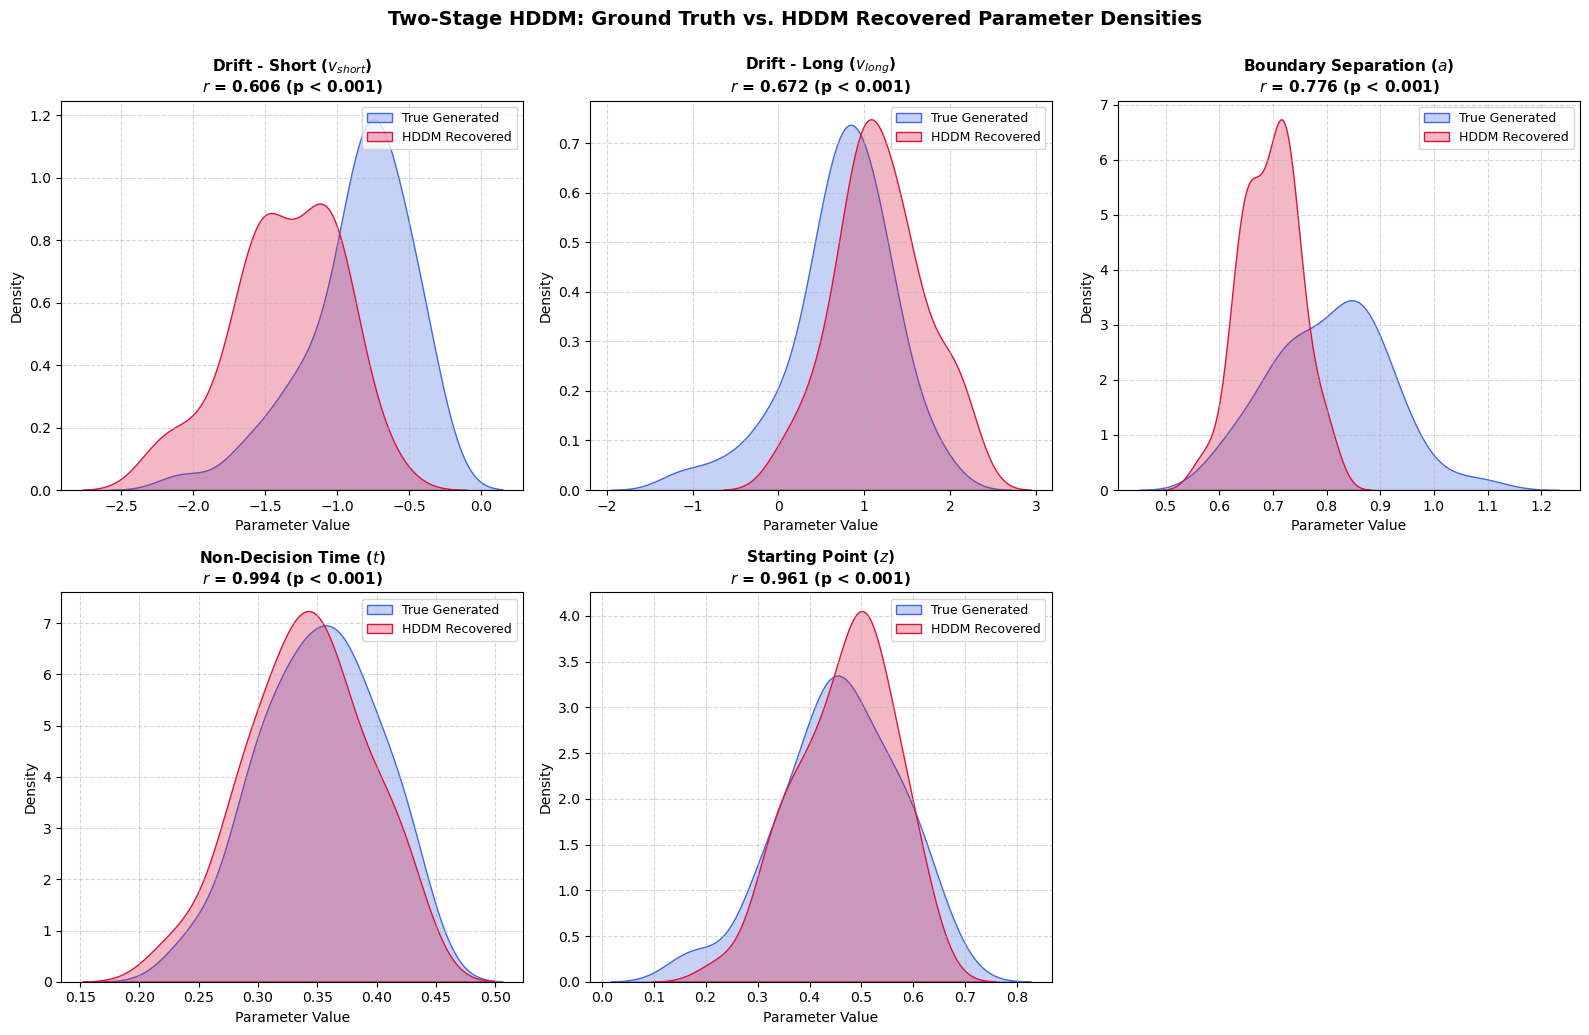

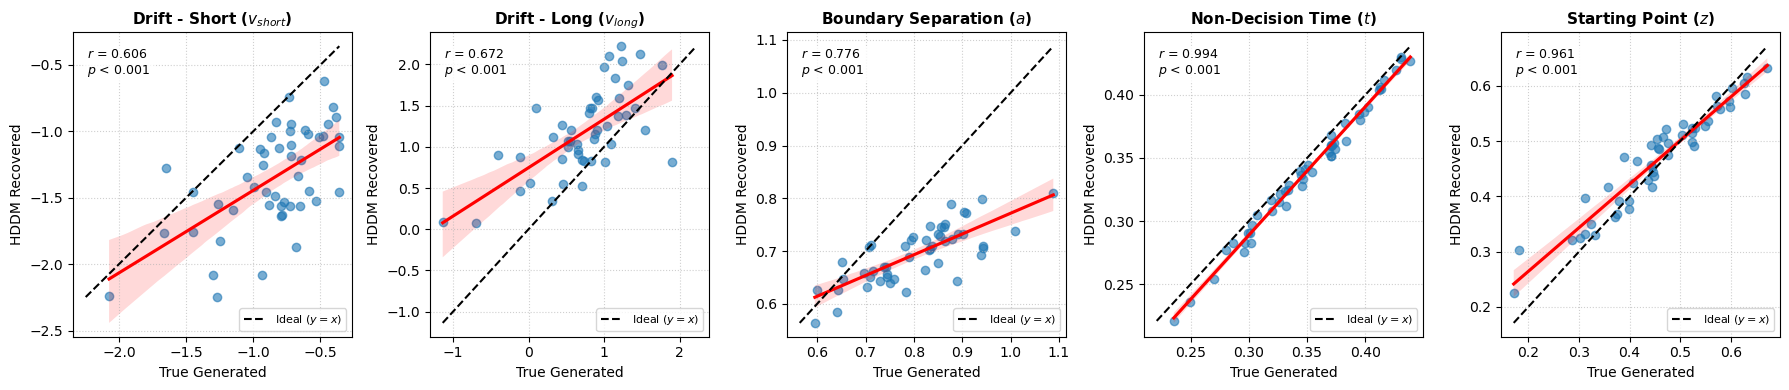

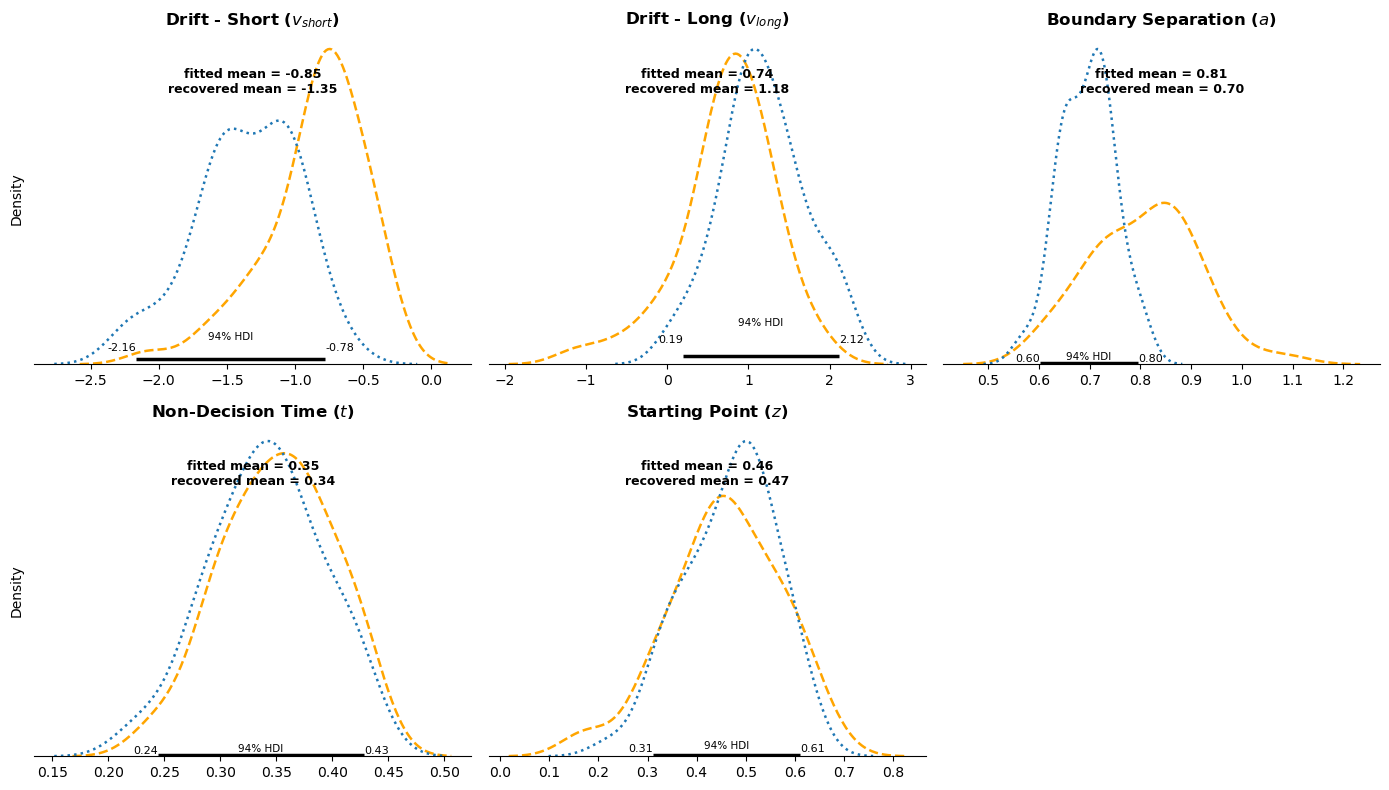

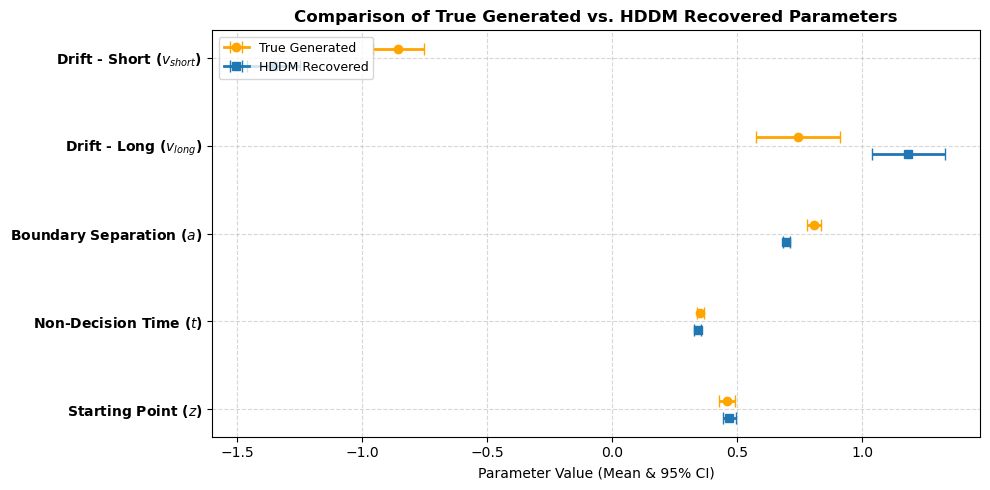


All sampling chains and diagnostic plots successfully completed and saved!


In [5]:
import os
import re
import multiprocessing as mp
import hddm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import pearsonr
import seaborn as sns

os.makedirs("parameter_recovery_output", exist_ok=True)
np.random.seed(40)

# ============================================================
# 1. TWO-STAGE HDDM SIMULATION FUNCTION
# ============================================================
def simulate_two_stage_hddm_bisection(
    n_subjects=50,
    trials_per_duration=10,
    durations=[0.5, 0.8, 1.1, 1.4, 1.7, 2.0],
    short_anchor=0.5,
    long_anchor=2.0,
    a_mean=0.8,
    t_mean=0.35,
    v1_mean=0.9,
    a_std=0.1,
    t_std=0.05,
    v1_std=0.2,
    dt=0.001,
    s=1.0,
    max_t=5.0
):
    """
    Simulates a Two-Stage Drift Diffusion Model for a Temporal Bisection Task.
    - Stage 1 (t < duration): Evidence accumulates during stimulus encoding.
    - Stage 2 (t >= duration): Stimulus ends. Drift switches based on accumulated offset vs threshold.
    """
    data = []
    subject_params = []
    anchor_mid = (short_anchor + long_anchor) / 2.0
    
    for subj in range(n_subjects):
        subj_a = np.maximum(0.2, np.random.normal(a_mean, a_std))
        subj_t = np.maximum(0.05, np.random.normal(t_mean, t_std))
        subj_v1 = np.maximum(0.0, np.random.normal(v1_mean, v1_std))
        
        subject_z2_trials = []
        short_v2_trials = []
        long_v2_trials = []
        
        for dur in durations:
            for trial in range(trials_per_duration):
                x1 = 0.0
                current_time = 0.0

                target = 2.0
                gamma = 0.2
                I_current = (subj_a / target) * subj_v1
                drift = I_current - (gamma * I_current)
                dcoeff = np.sqrt(I_current + (I_current * gamma)) * 0.1
                
                # --- STAGE 1: Stimulus Encoding Phase ---
                stage1_elapsed = 0.0
                terminated_in_stage1 = False
                
                while stage1_elapsed < dur:
                    x1 += drift * dt + np.sqrt(dt) * np.sqrt(drift) * dcoeff * np.random.normal(0, 1)
                    current_time += dt
                    stage1_elapsed += dt
                    
                    if x1 < 0:
                        x1 = -x1
                    
                    if x1 >= subj_a:
                        response = 1
                        rt = subj_t
                        terminated_in_stage1 = True
                        break

                if terminated_in_stage1:
                    data.append({
                        'subj_idx': subj,
                        'duration': dur,
                        'rt': rt,
                        'response': response,
                        'x_offset': x1
                    })
                    continue
                
                x_at_offset = x1
                x = x_at_offset
                stage2_elapsed = 0.0
                stage2_drift_this_trial = None
                stage2_z_this_trial = None

                # --- STAGE 2: Post-Offset Decision Phase ---
                while current_time < max_t:
                    k = 5.0
                    v_stage2 = k * (x - subj_a / 2.0)
                    stage2_drift_this_trial = v_stage2
                    stage2_z_this_trial = x
                    x += v_stage2 * dt + np.sqrt(dt) * s * np.random.normal(0, 1)
                    current_time += dt
                    stage2_elapsed += dt
                    
                    if x >= subj_a:
                        response = 1
                        rt = stage2_elapsed + subj_t
                        break
                    elif x <= 0:
                        response = 0
                        rt = stage2_elapsed + subj_t
                        break
                else:
                    response = np.nan
                    rt = np.nan
                
                if stage2_z_this_trial is not None:
                    subject_z2_trials.append(stage2_z_this_trial)
                
                if stage2_drift_this_trial is not None:
                    if x_at_offset < (subj_a / 2.0):
                        short_v2_trials.append(stage2_drift_this_trial)
                    else:
                        long_v2_trials.append(stage2_drift_this_trial)
                
                data.append({
                    'subj_idx': subj,
                    'duration': dur,
                    'rt': rt,
                    'response': response,
                    'x_offset': x_at_offset
                })

        subject_params.append({
            'subj_idx': subj,
            'v_true_short': np.mean(short_v2_trials) if short_v2_trials else np.nan,
            'v_true_long': np.mean(long_v2_trials) if long_v2_trials else np.nan,
            'a_true': subj_a,
            'z2_true': np.mean(subject_z2_trials) if subject_z2_trials else np.nan,
            't_true': subj_t
        })
        
    return pd.DataFrame(data), pd.DataFrame(subject_params)

# ============================================================
# 2. RUN SIMULATION & DATA PREPARATION
# ============================================================
print("Running Two-Stage Temporal Bisection Simulation...")
durations_to_test = [0.5, 0.8, 1.1, 1.4, 1.7, 2.0]
short_anchor, long_anchor = 0.5, 2.0
anchor_mid = (short_anchor + long_anchor) / 2.0

df_sim, df_true_parameters = simulate_two_stage_hddm_bisection(
    n_subjects=50,
    trials_per_duration=10,
    durations=durations_to_test,
    short_anchor=short_anchor,
    long_anchor=long_anchor
)

# Categorize duration class for condition-dependent drift rate fitting
df_sim['duration_class'] = np.where(df_sim['duration'] < anchor_mid, 'short', 'long').astype(str)

# Calculate normalized starting point (z2) relative to individual threshold (a_true)
df_sim_merged = df_sim.merge(df_true_parameters[['subj_idx', 'a_true']], on='subj_idx', how='left')
df_sim_merged['z2_normalized'] = (df_sim_merged['x_offset'] / df_sim_merged['a_true']).clip(0.0, 1.0)
df_subj_z2_mean = df_sim_merged.groupby('subj_idx')['z2_normalized'].mean().reset_index()
df_subj_z2_mean.rename(columns={'z2_normalized': 'mean_z2_normalized'}, inplace=True)
df_true_parameters['mean_z2_normalized'] = df_subj_z2_mean['mean_z2_normalized']

# ============================================================
# 3. TASK TRAJECTORIES AND BEHAVIORAL CURVES
# ============================================================
trajectory_data = []
a_s0 = df_true_parameters['a_true'].mean()
dt, max_t, s_noise = 0.001, 5.0, 1.0
durations_to_plot = [(2.0, '#d62728', 'Long Dur (2.0s)'), (1.25, '#2ca02c', 'Mid Dur (1.25s)'), (0.5, '#1f77b4', 'Short Dur (0.5s)')]

fig = plt.figure(figsize=(12, 11))
gs = fig.add_gridspec(3, 2, height_ratios=[1.2, 1, 1], hspace=0.4, wspace=0.3)

# Subplot A: Trajectories
ax_a = fig.add_subplot(gs[0, :])
for dur, color, label in durations_to_plot:
    for path_idx in range(20):
        x, t = 0.0, 0.0
        I_current = (a_s0 / 2.0) * 1.15
        drift = I_current - (0.2 * I_current)
        dcoeff = np.sqrt(I_current + (I_current * 0.2)) * 0.1
        
        t1_path, x1_path = [t], [x]
        stage1_elapsed = 0.0
        terminated_in_stage1 = False
        
        while stage1_elapsed < dur:
            x += drift * dt + np.sqrt(dt) * np.sqrt(drift) * dcoeff * np.random.normal(0, 1)
            t += dt
            stage1_elapsed += dt
            if x < 0: x = -x
            if x >= a_s0 or x <= 0:
                x = a_s0 if x >= a_s0 else 0.0
                t1_path.append(t); x1_path.append(x)
                terminated_in_stage1 = True
                break
            t1_path.append(t); x1_path.append(x)
            
        t2_path, x2_path = [], []
        if not terminated_in_stage1:
            t2_path, x2_path = [t], [x]
            while t < max_t:
                v_stage2 = 5.0 * (x - a_s0 / 2.0)
                x += v_stage2 * dt + np.sqrt(dt) * s_noise * np.random.normal(0, 1)
                t += dt
                if x >= a_s0 or x <= 0:
                    x = a_s0 if x >= a_s0 else 0.0
                    t2_path.append(t); x2_path.append(x)
                    break
                t2_path.append(t); x2_path.append(x)
        
        for time_val, x_val in zip(t1_path, x1_path):
            trajectory_data.append({'duration': dur, 'path_idx': path_idx, 'phase': 1, 'time': time_val, 'x': x_val})
        if not terminated_in_stage1 and len(t2_path) > 0:
            for time_val, x_val in zip(t2_path, x2_path):
                trajectory_data.append({'duration': dur, 'path_idx': path_idx, 'phase': 2, 'time': time_val, 'x': x_val})
        
        ax_a.plot(t1_path, x1_path, color=color, linestyle='--', alpha=0.6, label=f'{label} (Phase 1)' if path_idx == 0 else "")
        if not terminated_in_stage1 and len(t2_path) > 0:
            ax_a.plot(t2_path, x2_path, color=color, linestyle='-', alpha=0.9, label=f'{label} (Phase 2)' if path_idx == 0 else "")

pd.DataFrame(trajectory_data).to_csv('parameter_recovery_output/hddm_bisection_trajectories.csv', index=False)

ax_a.axhline(a_s0, color='gray', linestyle=':', alpha=0.7, label='Upper Threshold ($a$)')
ax_a.axhline(0, color='gray', linestyle=':', alpha=0.7, label='Lower Threshold ($0$)')
ax_a.set_xlabel("Time from Stimulus Onset (s)")
ax_a.set_ylabel("Decision Variable ($x$)")
ax_a.set_title("Two-Stage DDM Temporal Bisection Trajectories", fontweight='bold')
handles, labels_list = ax_a.get_legend_handles_labels()
ax_a.legend(dict(zip(labels_list, handles)).values(), dict(zip(labels_list, handles)).keys(), loc='upper left', bbox_to_anchor=(1, 1))

# Subplots B-E: Psychometric & RT Curves
ax_b = fig.add_subplot(gs[1, 0])
subj_psycho = df_sim.groupby(['subj_idx', 'duration'])['response'].mean().reset_index()
sample_subjs = subj_psycho['subj_idx'].unique()[:5]
palette = sns.color_palette("muted", 5)
for i, subj in enumerate(sample_subjs):
    subset = subj_psycho[subj_psycho['subj_idx'] == subj]
    ax_b.plot(subset['duration'], subset['response'], marker='o', color=palette[i], alpha=0.8, label=f'Subj {subj}')
ax_b.set_title('B. Psychometric Curves (First 5 Subjs)', fontsize=11, fontweight='bold')
ax_b.set_xlabel('Stimulus Duration (s)'); ax_b.set_ylabel('Proportion "Long" Response'); ax_b.grid(True, linestyle=':', alpha=0.6)

ax_c = fig.add_subplot(gs[1, 1])
pooled_psycho = df_sim.groupby('duration')['response'].agg(['mean', 'sem']).reset_index()
ax_c.errorbar(pooled_psycho['duration'], pooled_psycho['mean'], yerr=pooled_psycho['sem'], fmt='-o', color='#2ca02c', ecolor='gray', elinewidth=1.5, capsize=4, label='Pooled Mean ± SEM')
ax_c.set_title('C. Pooled Psychometric Curve', fontsize=11, fontweight='bold')
ax_c.set_xlabel('Stimulus Duration (s)'); ax_c.set_ylabel('Proportion "Long" Response'); ax_c.grid(True, linestyle=':', alpha=0.6)

ax_d = fig.add_subplot(gs[2, 0])
subj_rt = df_sim.groupby(['subj_idx', 'duration'])['rt'].mean().reset_index()
for i, subj in enumerate(sample_subjs):
    subset = subj_rt[subj_rt['subj_idx'] == subj]
    ax_d.plot(subset['duration'], subset['rt'], marker='s', color=palette[i], alpha=0.8, label=f'Subj {subj}')
ax_d.set_title('D. RT Curves (First 5 Subjs)', fontsize=11, fontweight='bold')
ax_d.set_xlabel('Stimulus Duration (s)'); ax_d.set_ylabel('Mean Response Time (s)'); ax_d.grid(True, linestyle=':', alpha=0.6)

ax_e = fig.add_subplot(gs[2, 1])
pooled_rt = df_sim.groupby('duration')['rt'].agg(['mean', 'sem']).reset_index()
ax_e.errorbar(pooled_rt['duration'], pooled_rt['mean'], yerr=pooled_rt['sem'], fmt='-s', color='#9467bd', ecolor='gray', elinewidth=1.5, capsize=4, label='Pooled Mean RT ± SEM')
ax_e.set_title('E. Pooled Response Time Curve', fontsize=11, fontweight='bold')
ax_e.set_xlabel('Stimulus Duration (s)'); ax_e.set_ylabel('Mean Response Time (s)'); ax_e.grid(True, linestyle=':', alpha=0.6)

plt.savefig('parameter_recovery_output/two_stage_bisection_trajectories.png', dpi=300, bbox_inches='tight')
plt.show()

# ============================================================
# 4. PREPROCESS DATA & RT DISTRIBUTION HISTOGRAM
# ============================================================
df_sim_flipped = hddm.utils.flip_errors(df_sim.copy())

fig = plt.figure(figsize=(10, 5), dpi=150)
ax = fig.add_subplot(111, xlabel='RT (s)', ylabel='Count', title='RT Distributions Across Subjects (Flipped Errors)')
for i, subj_data in df_sim_flipped.groupby('subj_idx'):
    subj_data.rt.hist(bins=60, histtype='step', ax=ax)

plt.tight_layout()
plt.savefig("parameter_recovery_output/rt_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

# ============================================================
# 5. PARALLEL SAMPLING HELPER FUNCTION
# ============================================================
def run_chain(chain_idx, data_df, queue):
    """Worker function to run a single MCMC chain in parallel."""
    print(f"Starting Chain {chain_idx + 1} on PID {os.getpid()}...")
    model = hddm.HDDM(
        data_df, 
        include=['v', 'a', 't', 'z'],
        depends_on={'v': 'duration_class'},
        p_outlier=0.05,
        informative=True,
        is_group_model=True
    )
    model.find_starting_values()
    model.sample(5000, burn=1000, dbname=f'traces_chain_{chain_idx}.db', db='pickle')
    queue.put((chain_idx, model))

if __name__ == '__main__':
    n_chains = 2
    queue = mp.Queue()
    processes = []

    print("\n[Parallel MCMC] Launching independent MCMC sampling chains...")
    for i in range(n_chains):
        p = mp.Process(target=run_chain, args=(i, df_sim, queue))
        processes.append(p)
        p.start()

    models_dict = {}
    for _ in range(n_chains):
        chain_idx, m = queue.get()
        models_dict[chain_idx] = m

    for p in processes:
        p.join()

    models = [models_dict[i] for i in range(n_chains)]

    # ============================================================
    # CONVERGENCE & MODEL SELECTION
    # ============================================================
    print("\n[Model Selection] DIC for all chains:")
    dic_values = [m.dic for m in models]
    for i, dic_val in enumerate(dic_values):
        print(f"  • Chain {i+1} DIC: {dic_val:.3f}")

    best_chain_idx = np.argmin(dic_values)
    model = models[best_chain_idx]
    print(f"\n=> Selecting Chain {best_chain_idx + 1} as primary model (Lowest DIC: {dic_values[best_chain_idx]:.3f})")

    print("\n[Convergence Diagnostic] Gelman-Rubin (R-hat) Statistics:")
    gr_stats = hddm.analyze.gelman_rubin(models)
    gr_df = pd.DataFrame.from_dict(gr_stats, orient='index', columns=['R_hat']).sort_values('R_hat', ascending=False)
    print(gr_df.head(15))

    # ============================================================
    # 6. PARAMETER EXTRACTION & RECOVERY EVALUATION
    # ============================================================
    rec_v_short, rec_v_long, rec_a, rec_t, rec_z = [], [], [], [], []
    n_subs = len(df_true_parameters)

    for subj in range(n_subs):
        v_short_val, v_long_val, a_val, t_val, z_val = np.nan, np.nan, np.nan, np.nan, np.nan
        for idx_name in model.nodes_db.index:
            name_str = str(idx_name)
            if f".{subj}" in name_str or f"({subj})" in name_str:
                if 'v_' in name_str or 'v(' in name_str:
                    if 'short' in name_str.lower():
                        v_short_val = model.nodes_db.loc[idx_name, "mean"]
                    elif 'long' in name_str.lower():
                        v_long_val = model.nodes_db.loc[idx_name, "mean"]
                if name_str == f"a_subj.{subj}" or name_str == f"a.{subj}":
                    a_val = model.nodes_db.loc[idx_name, "mean"]
                elif name_str == f"t_subj.{subj}" or name_str == f"t.{subj}":
                    t_val = model.nodes_db.loc[idx_name, "mean"]
                elif name_str == f"z_subj.{subj}" or name_str == f"z.{subj}":
                    z_val = model.nodes_db.loc[idx_name, "mean"]

        rec_v_short.append(v_short_val)
        rec_v_long.append(v_long_val)
        rec_a.append(a_val)
        rec_t.append(t_val)
        rec_z.append(z_val)

    merged_df = df_true_parameters.copy()
    merged_df["v2_rec_short"] = rec_v_short
    merged_df["v2_rec_long"] = rec_v_long
    merged_df["a2_recovered"] = rec_a
    merged_df["t2_recovered"] = rec_t
    merged_df["z2_recovered"] = rec_z

    merged_df.to_csv("parameter_recovery_output/stage2_recovered_parameters.csv", index=False)
    print("\nRecovered parameters successfully saved to 'parameter_recovery_output/stage2_recovered_parameters.csv'!")

    # Evaluation Pairs
    corr_pairs = [
        ("v_true_short", "v2_rec_short", "Drift - Short ($v_{short}$)"),
        ("v_true_long", "v2_rec_long", "Drift - Long ($v_{long}$)"),
        ("a_true", "a2_recovered", "Boundary Separation ($a$)"),
        ("t_true", "t2_recovered", "Non-Decision Time ($t$)"),
        ("mean_z2_normalized", "z2_recovered", "Starting Point ($z$)")
    ]

    # ============================================================
    # PLOT 1: DENSITY COMPARISON PLOTS (KDE)
    # ============================================================
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    axes = axes.flatten()

    for i, (true_col, rec_col, title) in enumerate(corr_pairs):
        ax = axes[i]
        if true_col in merged_df.columns and rec_col in merged_df.columns:
            sub_df = merged_df[[true_col, rec_col]].apply(pd.to_numeric, errors="coerce").dropna()

            sns.kdeplot(data=sub_df[true_col], ax=ax, color="royalblue", fill=True, alpha=0.3, label="True Generated")
            sns.kdeplot(data=sub_df[rec_col], ax=ax, color="crimson", fill=True, alpha=0.3, label="HDDM Recovered")

            r, p_val = pearsonr(sub_df[true_col], sub_df[rec_col])
            p_str = "p < 0.001" if p_val < 0.001 else f"p = {p_val:.3f}"

            ax.set_title(f"{title}\n$r$ = {r:.3f} ({p_str})", fontsize=11, fontweight="bold")
            ax.set_xlabel("Parameter Value")
            ax.set_ylabel("Density")
            ax.legend(loc="upper right", fontsize=9)
            ax.grid(True, linestyle="--", alpha=0.5)

    fig.delaxes(axes[5])
    plt.tight_layout()
    plt.suptitle("Two-Stage HDDM: Ground Truth vs. HDDM Recovered Parameter Densities", y=1.03, fontsize=14, weight="bold")
    plt.savefig("parameter_recovery_output/two_stage_parameter_recovery_density.png", dpi=300, bbox_inches="tight")
    plt.show()

    # ============================================================
    # PLOT 2: INDIVIDUAL CORRELATION SCATTER WITH IDENTITY LINES (y = x)
    # ============================================================
    def regplot_with_corr(x, y, ax, title):
        sub_df = pd.DataFrame({'x': x, 'y': y}).dropna()
        if len(sub_df) < 2:
            ax.text(0.5, 0.5, "Insufficient data", ha='center', va='center')
            return
        r, p_val = pearsonr(sub_df['x'], sub_df['y'])
        p_str = "$p$ < 0.001" if p_val < 0.001 else f"$p$ = {p_val:.3f}"
        
        sns.regplot(data=sub_df, x='x', y='y', ax=ax, scatter_kws={'alpha': 0.6, 'color': '#1f77b4'}, line_kws={'color': 'red'})
        
        min_val = min(sub_df['x'].min(), sub_df['y'].min())
        max_val = max(sub_df['x'].max(), sub_df['y'].max())
        ax.plot([min_val, max_val], [min_val, max_val], 'k--', lw=1.5, label='Ideal ($y=x$)')
        
        text = f"$r$ = {r:.3f}\n{p_str}"
        ax.text(0.05, 0.95, text, transform=ax.transAxes, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='none'), fontsize=9)
        ax.set_title(title, fontsize=11, fontweight='bold')
        ax.set_xlabel("True Generated")
        ax.set_ylabel("HDDM Recovered")
        ax.legend(loc='lower right', fontsize=8)
        ax.grid(True, linestyle=':', alpha=0.6)

    fig, axes = plt.subplots(ncols=len(corr_pairs), figsize=(18, 4))
    for i, (true_col, rec_col, title) in enumerate(corr_pairs):
        if true_col in merged_df.columns and rec_col in merged_df.columns:
            sub_df = merged_df[[true_col, rec_col]].dropna()
            regplot_with_corr(x=sub_df[true_col], y=sub_df[rec_col], ax=axes[i], title=title)

    plt.tight_layout()
    plt.savefig("parameter_recovery_output/two_stage_parameter_recovery_scatter.png", dpi=300, bbox_inches='tight')
    plt.show()

    # ============================================================
    # PLOT 3: ARVIZ-STYLE OVERLAY WITH 94% HDI
    # ============================================================
    fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(14, 8))
    axes = axes.flatten()

    for i, (true_col, rec_col, param_name) in enumerate(corr_pairs):
        ax = axes[i]
        if true_col in merged_df.columns and rec_col in merged_df.columns:
            sub_df = merged_df[[true_col, rec_col]].apply(pd.to_numeric, errors='coerce').dropna()
            
            vals_true = sub_df[true_col].values
            vals_rec = sub_df[rec_col].values
            
            mean_true = np.mean(vals_true)
            mean_rec = np.mean(vals_rec)
            hdi_rec = np.percentile(vals_rec, [3, 97])
            
            sns.kdeplot(x=vals_true, ax=ax, color="orange", linestyle="dashed", label="fitted", lw=1.8)
            sns.kdeplot(x=vals_rec, ax=ax, color="tab:blue", linestyle="dotted", label="recovered", lw=1.8)
            
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_visible(False)
            ax.set_yticks([])
            ax.set_ylabel('Density' if i % 3 == 0 else '', fontsize=10)
            ax.set_title(param_name, fontsize=12, fontweight='bold')
            
            ax.text(0.5, 0.82, f"fitted mean = {mean_true:.2f}\nrecovered mean = {mean_rec:.2f}", 
                    transform=ax.transAxes, ha='center', fontsize=9, fontweight='bold')
            
            ax.hlines(y=0.02, xmin=hdi_rec[0], xmax=hdi_rec[1], color='black', linewidth=2.5)
            ax.text(hdi_rec[0], 0.05, f"{hdi_rec[0]:.2f}", ha='right', fontsize=8)
            ax.text(hdi_rec[1], 0.05, f"{hdi_rec[1]:.2f}", ha='left', fontsize=8)
            ax.text(np.mean(hdi_rec), 0.09, "94% HDI", ha='center', fontsize=7.5)

    fig.delaxes(axes[5])
    plt.tight_layout()
    plt.savefig("parameter_recovery_output/arviz_style_direct_plot.png", dpi=300, bbox_inches='tight')
    plt.show()

    # ============================================================
    # PLOT 4: COMPARATIVE FOREST PLOT (MEANS & 95% CI)
    # ============================================================
    fig, ax = plt.subplots(figsize=(10, 5))

    y_ticks = np.arange(len(corr_pairs))
    labels = [p[2] for p in corr_pairs]

    for idx, (true_col, rec_col, title) in enumerate(corr_pairs):
        sub_df = merged_df[[true_col, rec_col]].apply(pd.to_numeric, errors='coerce').dropna()
        
        true_mean = sub_df[true_col].mean()
        true_ci = 1.96 * sub_df[true_col].sem()
        
        rec_mean = sub_df[rec_col].mean()
        rec_ci = 1.96 * sub_df[rec_col].sem()
        
        ax.errorbar(true_mean, idx - 0.1, xerr=true_ci, fmt='o-', color='orange', label='True Generated' if idx == 0 else "", capsize=4, lw=2)
        ax.errorbar(rec_mean, idx + 0.1, xerr=rec_ci, fmt='s-', color='tab:blue', label='HDDM Recovered' if idx == 0 else "", capsize=4, lw=2)

    ax.set_yticks(y_ticks)
    ax.set_yticklabels(labels, fontweight='bold')
    ax.invert_yaxis()
    ax.set_xlabel("Parameter Value (Mean & 95% CI)")
    ax.set_title("Comparison of True Generated vs. HDDM Recovered Parameters", fontsize=12, fontweight='bold')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.savefig("parameter_recovery_output/direct_forest_plot.png", dpi=300, bbox_inches='tight')
    plt.show()

    print("\nAll sampling chains and diagnostic plots successfully completed and saved!")

Plotting a
Plotting a_std
Plotting v(long)
Plotting v(short)
Plotting v_std
Plotting t
Plotting t_std
Plotting z
Plotting z_std


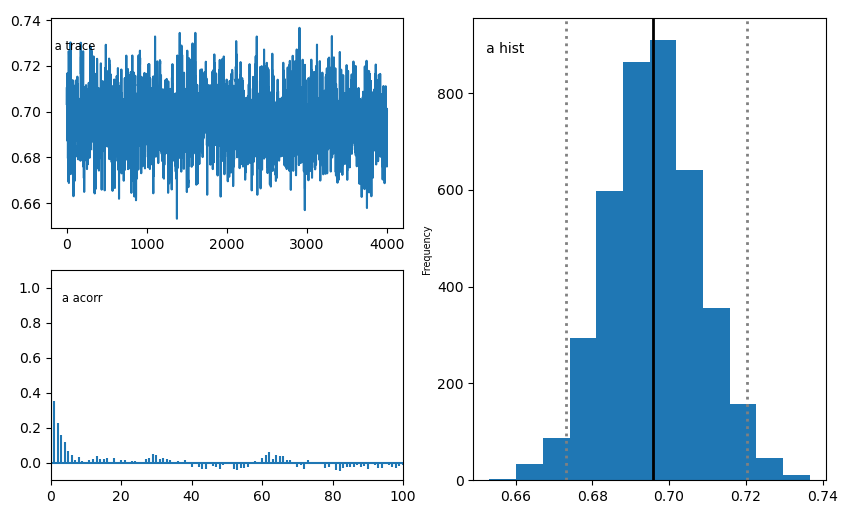

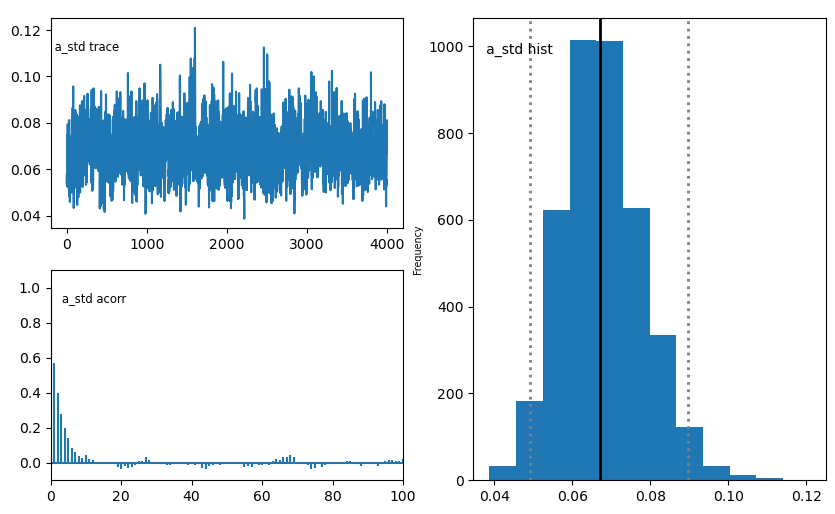

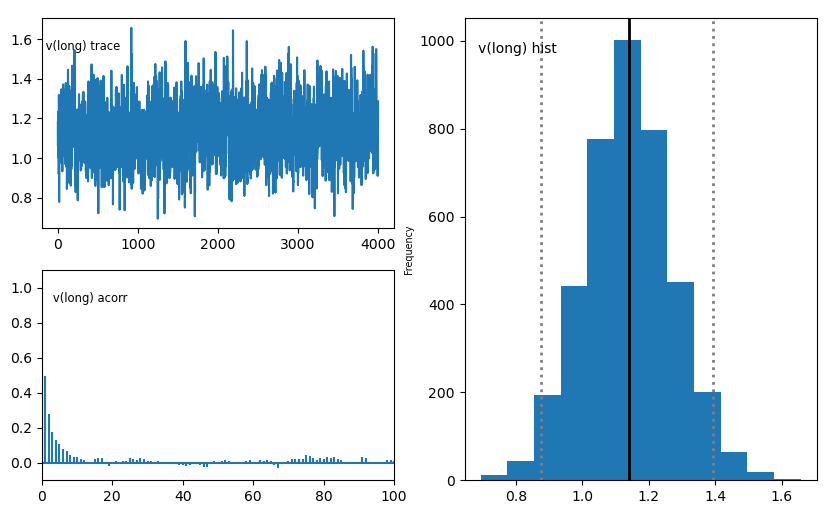

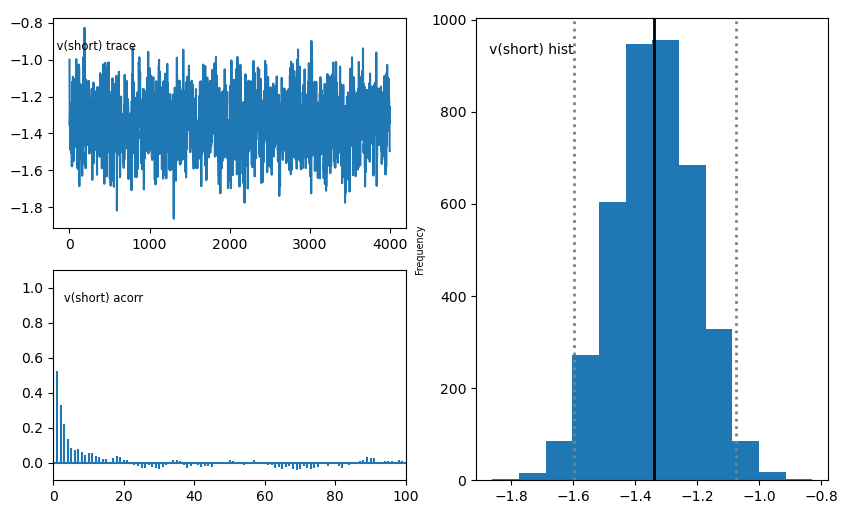

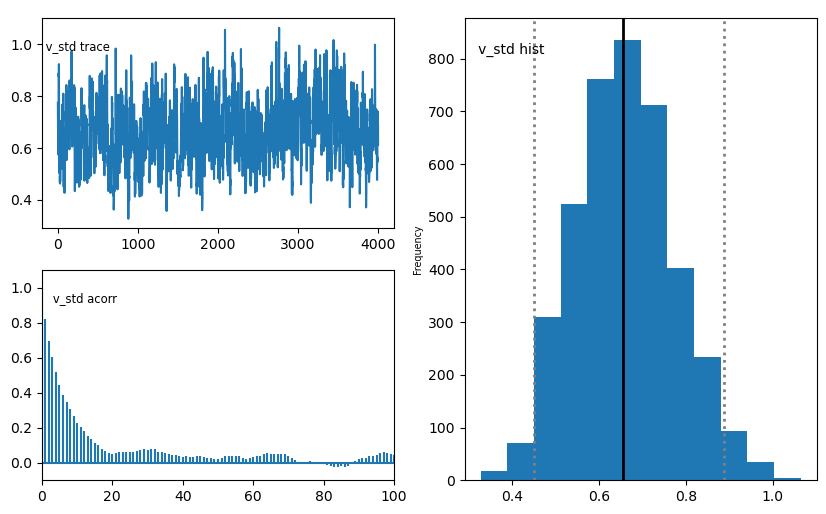

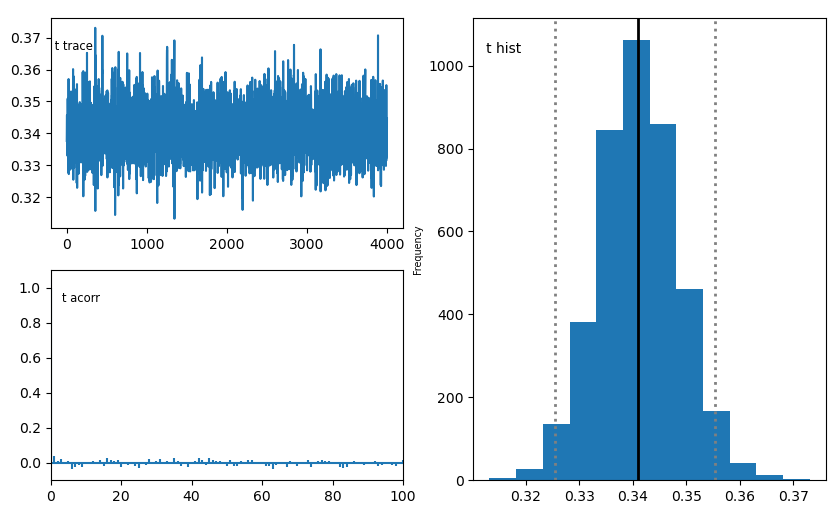

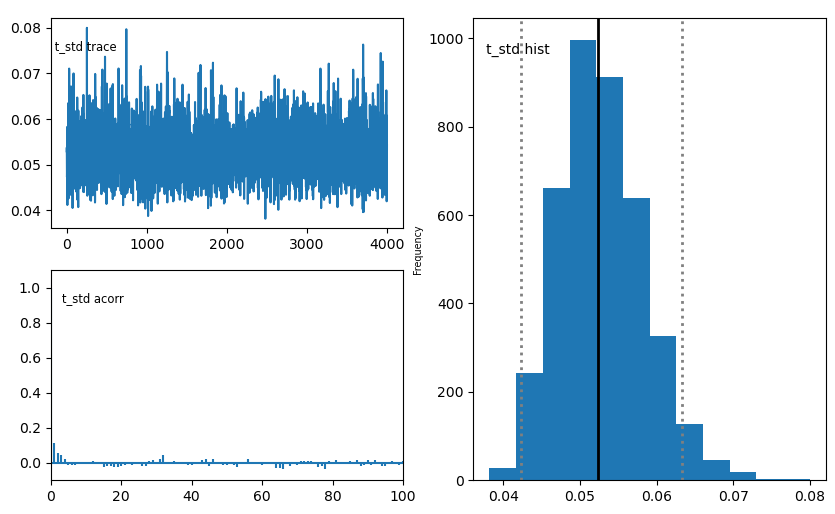

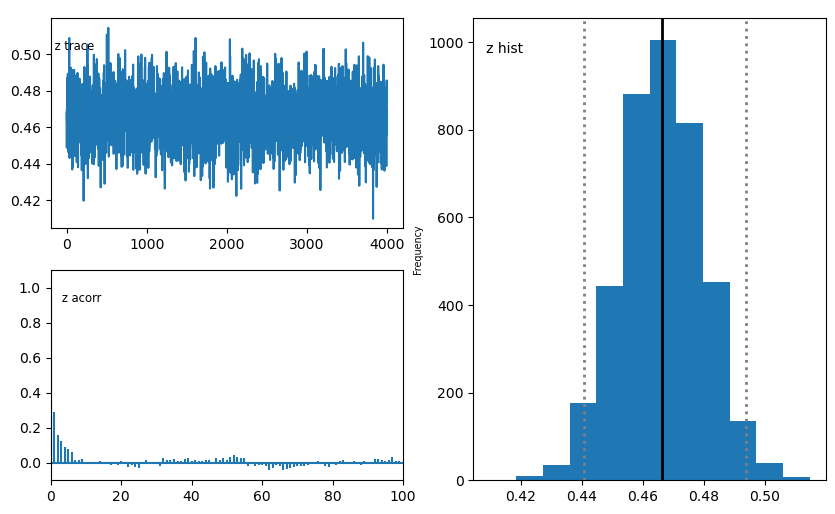

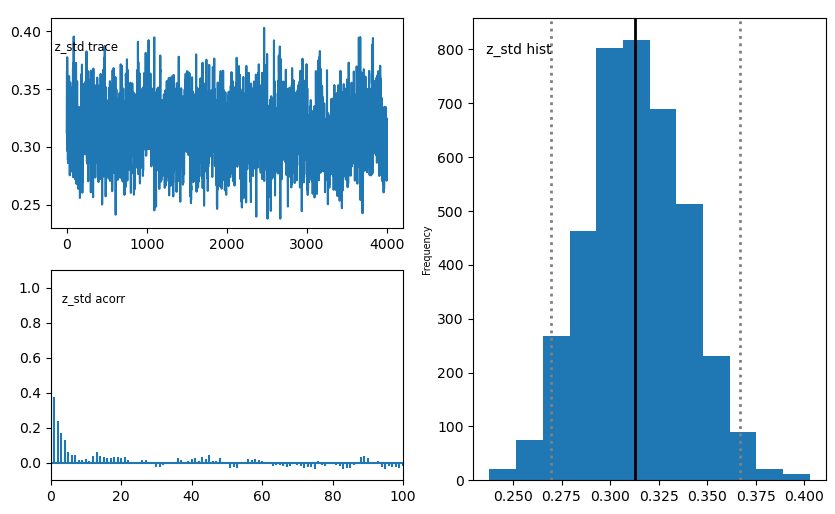

In [7]:
model.plot_posteriors()